# Flujo sobre un escalón descendente
**Mecánica de Fluidos · Proyecto final**

Un fluido viene por un canal, encuentra un escalón hacia abajo y el canal se ensancha al doble. El flujo **no puede
dar la vuelta a la esquina**: se despega, deja atrás un remolino (zona de recirculación) y se vuelve a pegar al piso más
adelante. Este notebook resuelve las **ecuaciones de Navier–Stokes** en la computadora para ver ese remolino, medir
qué tan largo es y filmar cómo se forma.

**Cómo usarlo:** *Kernel → Restart & Run All* (unos 13 min con videos, ~5 min con `HACER_VIDEOS = False`).
Necesita `numpy`, `scipy`, `matplotlib` y, para los videos, `imageio-ffmpeg` (`pip install imageio-ffmpeg`).

| Bloque | Qué hay |
|---|---|
| 0 | Librerías y parámetros (cambiar `RE` aquí para la demo en vivo) |
| 1 | La física: ecuaciones, condiciones de frontera, supuestos |
| 2 | La idea del método numérico en 3 pasos |
| 3 | El código, función por función |
| 4 | Caso base y video del arranque |
| 5 | Análisis paramétrico: viscosidad (Re), malla y paso de tiempo |
| 6 | Comparación con la literatura y conclusiones |

Se partió del notebook *Combined backward facing step* (kangluosee/CFD-Python) como referencia del problema;
el código de aquí se escribió desde cero con un método distinto.

## 0. Librerías y parámetros

In [1]:
import numpy as np                       # arreglos y operaciones vectorizadas
import scipy.sparse as sps               # matrices dispersas (casi todo ceros)
import scipy.sparse.linalg as spla       # resolver sistemas lineales dispersos
import matplotlib.pyplot as plt          # gráficas
import matplotlib.patches as patches     # para dibujar el escalón
import subprocess                        # para llamar a ffmpeg (videos)
from pathlib import Path
from IPython.display import Video, display
try:                                     # ffmpeg portátil (pip install imageio-ffmpeg); si no, el del sistema
    import imageio_ffmpeg
    plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
except ImportError:
    pass

FIG = Path("figures")                    # carpeta donde se guardan las figuras
FIG.mkdir(exist_ok=True)

In [2]:
# ======================= PARÁMETROS (cambiar aquí en la demo en vivo) =======================
RE = 200        # número de Reynolds  Re = U*H/nu  (bajar nu = subir Re)
NY = 20         # número de celdas en la altura del canal
L  = 15.0       # largo del canal después del escalón (en alturas H)
HACER_VIDEOS = True   # False = saltar los videos (el notebook corre en ~5 min en vez de ~13)
# ===========================================================================================

H  = 1.0        # altura del canal después del escalón
S  = 0.5        # altura del escalón
U  = 1.0        # velocidad media a la entrada
LI = 2.0        # largo del canal de entrada antes del escalón
CFL = 0.5       # fracción del límite de estabilidad que usamos para dt

## 1. La física

### Geometría
El fluido llega por un canal de altura $h = H/2$ y largo $2H$; en $x = 0$ hay un escalón de altura $S = H/2$ y el canal
**se ensancha al doble** (altura $H = 1$). Es la geometría estándar de los estudios numéricos de este problema.

### Ecuaciones (las de clase, en forma adimensional)
$$\frac{\partial u}{\partial x} + \frac{\partial v}{\partial y} = 0 \qquad \text{(continuidad: no se crea ni se pierde masa)}$$
$$\frac{\partial u}{\partial t} + \underbrace{\frac{\partial (uu)}{\partial x} + \frac{\partial (vu)}{\partial y}}_{\text{convección}} = -\frac{\partial p}{\partial x} + \underbrace{\frac{1}{Re}\left(\frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2}\right)}_{\text{difusión viscosa}}$$
$$\frac{\partial v}{\partial t} + \frac{\partial (uv)}{\partial x} + \frac{\partial (vv)}{\partial y} = -\frac{\partial p}{\partial y} + \frac{1}{Re}\left(\frac{\partial^2 v}{\partial x^2} + \frac{\partial^2 v}{\partial y^2}\right)$$

Se midió todo en unidades de $H$ (longitud), $U$ (velocidad media de entrada) y $\rho U^2$ (presión). Así sólo queda un
parámetro, el **número de Reynolds** $Re = UH/\nu$: inercia contra viscosidad. **Bajar la viscosidad es lo mismo que subir $Re$.**

> La convección se escribe como $\partial(uu)/\partial x + \partial(vu)/\partial y$ en vez de $u\,\partial u/\partial x + v\,\partial u/\partial y$:
> es lo mismo gracias a la continuidad, y esta forma ("lo que sale menos lo que entra") conserva mejor el momento.

### Supuestos
2D, incompresible ($\rho$ constante), newtoniano ($\nu$ constante), sin cambios de temperatura, laminar ($Re \le 600$),
sin gravedad (sólo añade presión hidrostática y no cambia el movimiento).

### Condiciones de frontera e inicial
| Dónde | Velocidad | Presión |
|---|---|---|
| Entrada ($x=-2H$) | parábola de Poiseuille, $u = 6U\eta(1-\eta)$, $v = 0$ | $\partial p/\partial n = 0$ |
| Escalón (tapa y cara vertical) | $u = v = 0$ (no deslizamiento) | $\partial p/\partial n = 0$ |
| Piso y techo | $u = v = 0$ (no deslizamiento) | $\partial p/\partial n = 0$ |
| Salida ($x = L$) | $\partial u/\partial x = \partial v/\partial x = 0$ (flujo ya desarrollado) | $p = 0$ (referencia) |

**Condición inicial:** fluido quieto, $u = v = 0$. Se avanza en el tiempo hasta que el flujo deja de cambiar (estado estacionario).

### ¿Qué esperamos ver?
Al llegar a la esquina, el fluido pegado a la pared no tiene suficiente inercia para seguir el cambio de geometría contra el
aumento de presión del ensanchamiento: **se separa**. Debajo queda un remolino con $u < 0$. Más adelante el chorro se abre,
toca el piso en el **punto de reacoplamiento** $x_r$ (ahí el esfuerzo cortante en la pared es cero) y el perfil vuelve a ser
una parábola. A mayor $Re$ el remolino es más largo, y a partir de $Re \approx 400$ aparece un segundo remolino en el techo.

## 2. La idea del método numérico

**Discretizar:** partimos el canal en celdas cuadradas de lado $\Delta x$ y cambiamos cada derivada por una diferencia, por ejemplo
$$\frac{\partial^2 u}{\partial x^2} \approx \frac{u_E - 2u_P + u_W}{\Delta x^2}, \qquad \frac{\partial p}{\partial x} \approx \frac{p_{derecha} - p_{izquierda}}{\Delta x}$$
($P$ = el punto, $E, W, N, S$ = vecinos este, oeste, norte, sur). El escalón es simplemente un bloque de celdas sólidas.

**Malla escalonada:** la presión se guarda en el centro de cada celda y las velocidades en las caras. Así la velocidad de
cada cara queda justo entre dos presiones y la diferencia de presión es la fuerza que la empuja.

![malla](figures/malla_escalonada.png)

**El problema de la presión:** no hay una ecuación "para $p$"; la presión es lo que se necesita para que se cumpla la
continuidad. Por eso cada paso de tiempo $\Delta t$ se hace en **3 pasos** (método de proyección de Chorin, 1968):

1. **Velocidad de prueba** con convección y difusión, ignorando la presión:
   $u^* = u^n + \Delta t\,A$, donde $A$ = difusión − convección.
2. **Presión:** $u^*$ no cumple continuidad. Buscamos la $p$ que la corrige; sale de tomar la divergencia del paso 3:
   $$\nabla^2 p = \frac{\nabla \cdot \mathbf{u}^*}{\Delta t}$$
   Es un sistema lineal $A\,p = b$ (una ecuación por celda), que se resuelve con la computadora.
3. **Corrección:** $\mathbf{u}^{n+1} = \mathbf{u}^* - \Delta t\,\nabla p$. Ahora $\nabla\cdot\mathbf{u}^{n+1} = 0$.

**Convección:** el valor de $u$ en la cara entre dos nodos es el **promedio** de los dos. Es la opción más simple y precisa
(error proporcional a $\Delta x^2$).

**Avance en el tiempo (Adams–Bashforth):** la forma más simple, $u^* = u^n + \Delta t\,A^n$ (Euler), usa la aceleración del
inicio del paso. Con convección por promedio eso **explota** (lo probamos en 5.3): los errores crecen un poco en cada paso.
La solución es estimar la aceleración **a la mitad del paso** extrapolando con la del paso anterior:
$$A^{n+1/2} \approx A^n + \tfrac{1}{2}\left(A^n - A^{n-1}\right) = \tfrac{3}{2}A^n - \tfrac{1}{2}A^{n-1}$$
Es una sola línea más de código y deja el cálculo estable y preciso.

**Estabilidad (condición CFL):** en un paso de tiempo el fluido no debe avanzar más de una celda:
$\Delta t \le \Delta x / u_{max}$. Usamos la mitad de ese límite (`CFL = 0.5`).

## 3. El código
### 3.1 Malla y perfil de entrada

In [3]:
def crear_malla(NY, L):
    """Celdas cuadradas de lado dx sobre [-LI, L] x [0, H]. El escalón es el bloque sólido x < 0, y < S."""
    dx = H / NY                              # lado de cada celda
    NX = round((LI + L) / dx)                # número de celdas a lo largo
    x_p = (np.arange(NX) + 0.5) * dx - LI    # x de los centros de celda (donde vive p)
    y_p = (np.arange(NY) + 0.5) * dx         # y de los centros de celda
    x_u = np.arange(NX + 1) * dx - LI        # x de las caras verticales (donde vive u)
    solido = (x_p[:, None] < 0) & (y_p[None, :] < S)     # True en las celdas del escalón
    return dict(NX=NX, NY=NY, dx=dx, L=L, x_p=x_p, y_p=y_p, x_u=x_u, solido=solido,
                I0=round(LI / dx),           # índice de la cara x = 0 (la cara del escalón)
                J0=round(S / dx))            # número de filas de celdas bajo y = S


def perfil_entrada(y):
    """Perfil parabólico (flujo de Poiseuille) en el canal de entrada S < y < H."""
    eta = (y - S) / (H - S)                  # 0 en la tapa del escalón, 1 en el techo
    return np.where(y > S, 6 * U * eta * (1 - eta), 0.0)   # el 6 hace que la velocidad media sea U

### 3.2 Matriz de la ecuación de presión (paso 2)

In [4]:
def matriz_presion(m):
    """Arma y factoriza la matriz de la ecuación de Poisson  lap(p) = b.

    Para cada celda con fluido: sum_vecinos (p_vecino - p_celda) / dx^2 = b_celda.
    - Paredes, entrada y escalón: dp/dn = 0  -> ese vecino simplemente no se suma.
    - Salida: p = 0 en la cara, que está a dx/2 del centro -> aporta -2 p_celda / dx^2.
    """
    NX, NY, solido = m["NX"], m["NY"], m["solido"]
    A = sps.lil_matrix((NX * NY, NX * NY))   # una ecuación por celda; matriz fácil de llenar
    for i in range(NX):                      # columnas de celdas (dirección x)
        for j in range(NY):                  # filas de celdas (dirección y)
            k = i * NY + j                   # número de la celda (i, j) en la lista
            if solido[i, j]:                 # dentro del escalón no hay fluido: ecuación trivial p = 0
                A[k, k] = 1; continue
            for vi, vj in [(i + 1, j), (i - 1, j), (i, j + 1), (i, j - 1)]:    # los 4 vecinos
                if vi == NX:                                                   # derecha de la última: la salida
                    A[k, k] -= 2
                elif vi >= 0 and 0 <= vj < NY and not solido[vi, vj]:         # vecino con fluido
                    A[k, vi * NY + vj] = 1; A[k, k] -= 1
    return spla.splu(A.tocsc() / m["dx"]**2) # factorización LU: se hace UNA vez y se reutiliza

### 3.3 Condiciones de frontera
Cada arreglo tiene una fila extra de **celdas fantasma** fuera del dominio. Para que la velocidad sea cero *sobre* una
pared que queda entre dos nodos, el fantasma toma el valor opuesto (espejo): el promedio de los dos da cero justo en la pared.

In [5]:
def fronteras(u, v, u_entrada, m):
    """Condiciones de frontera. u tiene forma (NX+1, NY+2) y v (NX+2, NY+1):
    incluyen una 'celda fantasma' fuera del dominio para poner las paredes."""
    I0, J0 = m["I0"], m["J0"]
    u[0, 1:-1] = u_entrada           # entrada: perfil parabólico
    v[0, :] = -v[1, :]               # entrada: v = 0 (fantasma espejo: el promedio en la frontera da cero)
    u[:I0 + 1, 1:J0 + 1] = 0.0       # escalón: u = 0 dentro del bloque y en su cara vertical
    v[1:I0 + 1, :J0 + 1] = 0.0       # escalón: v = 0 dentro del bloque y en su tapa
    u[:I0, J0] = -u[:I0, J0 + 1]     # tapa del escalón: no deslizamiento (fantasma espejo)
    v[I0, 1:J0] = -v[I0 + 1, 1:J0]   # cara vertical del escalón: no deslizamiento
    u[:, 0] = -u[:, 1]               # piso: u = 0
    u[:, -1] = -u[:, -2]             # techo: u = 0
    v[:, 0] = 0.0                    # piso: v = 0 (v está justo sobre la pared)
    v[:, -1] = 0.0                   # techo: v = 0
    v[-1, :] = v[-2, :]              # salida: dv/dx = 0

### 3.4 Convección y difusión (paso 1)

In [6]:
def aceleracion_u(u, v, nu, dx):
    """Ecuación de x sin la presión:  nu*lap(u) - d(uu)/dx - d(vu)/dy."""
    P = u[1:-1, 1:-1]                                     # u en el nodo
    E, W = u[2:, 1:-1], u[:-2, 1:-1]                      # vecinos este y oeste
    N, Sur = u[1:-1, 2:], u[1:-1, :-2]                    # vecinos norte y sur
    difusion = nu * (E + W + N + Sur - 4 * P) / dx**2     # laplaciano de 5 puntos

    u_e, u_w = (P + E) / 2, (W + P) / 2                   # u en las caras este y oeste (promedio)
    u_n, u_s = (P + N) / 2, (Sur + P) / 2                 # u en las caras norte y sur
    v_n = (v[1:-2, 1:] + v[2:-1, 1:]) / 2                 # v que cruza la cara norte
    v_s = (v[1:-2, :-1] + v[2:-1, :-1]) / 2               # v que cruza la cara sur
    conveccion = (u_e * u_e - u_w * u_w) / dx + (v_n * u_n - v_s * u_s) / dx   # lo que sale - lo que entra
    return difusion - conveccion


def aceleracion_v(u, v, nu, dx):
    """Ecuación de y sin la presión:  nu*lap(v) - d(uv)/dx - d(vv)/dy."""
    P = v[1:-1, 1:-1]
    E, W = v[2:, 1:-1], v[:-2, 1:-1]
    N, Sur = v[1:-1, 2:], v[1:-1, :-2]
    difusion = nu * (E + W + N + Sur - 4 * P) / dx**2

    v_e, v_w = (P + E) / 2, (W + P) / 2                   # v en las caras este y oeste
    v_n, v_s = (P + N) / 2, (Sur + P) / 2                 # v en las caras norte y sur
    u_e = (u[1:, 1:-2] + u[1:, 2:-1]) / 2                 # u que cruza la cara este
    u_w = (u[:-1, 1:-2] + u[:-1, 2:-1]) / 2               # u que cruza la cara oeste
    conveccion = (u_e * v_e - u_w * v_w) / dx + (v_n * v_n - v_s * v_s) / dx
    return difusion - conveccion

### 3.5 El ciclo en el tiempo: los 3 pasos

In [7]:
def simular(Re, NY=20, L=15.0, dt=None, t_max=400.0, tol=1e-4, fotos_cada=0, ab2=True):
    """Resuelve Navier-Stokes desde el reposo hasta que el flujo deja de cambiar."""
    nu = 1.0 / Re                            # viscosidad adimensional
    m = crear_malla(NY, L)
    NX, dx = m["NX"], m["dx"]
    if dt is None:
        dt = CFL * dx / 1.5                  # límite CFL: dt = dx / u_max, con u_max = 1.5 U

    resolver_p = matriz_presion(m)           # matriz de presión, factorizada una sola vez
    u_entrada = perfil_entrada(m["y_p"])
    u = np.zeros((NX + 1, NY + 2))           # condición inicial: fluido en reposo
    v = np.zeros((NX + 2, NY + 1))
    fronteras(u, v, u_entrada, m)

    t, n, estado = 0.0, 0, "tiempo máximo"
    hist_t, hist_cambio, fotos = [], [], []
    Au_ant = Av_ant = None                   # aceleraciones del paso anterior (para Adams-Bashforth)
    while t < t_max:
        u_viejo = u.copy()

        # PASO 1: velocidad de prueba con convección y difusión, SIN presión.
        # Adams-Bashforth: la aceleración a la mitad del paso se estima como 1.5*(la de ahora) - 0.5*(la anterior)
        Au, Av = aceleracion_u(u, v, nu, dx), aceleracion_v(u, v, nu, dx)
        if Au_ant is None or not ab2:
            Au_ant, Av_ant = Au, Av          # primer paso (o ab2=False): Euler simple
        u_est, v_est = u.copy(), v.copy()
        u_est[1:-1, 1:-1] += dt * (1.5 * Au - 0.5 * Au_ant)
        v_est[1:-1, 1:-1] += dt * (1.5 * Av - 0.5 * Av_ant)
        Au_ant, Av_ant = Au, Av
        u_est[-1, 1:-1] = u_est[-2, 1:-1]    # salida: du/dx = 0
        fronteras(u_est, v_est, u_entrada, m)

        # PASO 2: presión que hace falta para que no se cree ni se pierda masa:  lap(p) = div(u_est)/dt
        div = (u_est[1:, 1:-1] - u_est[:-1, 1:-1] + v_est[1:-1, 1:] - v_est[1:-1, :-1]) / dx
        div[m["solido"]] = 0.0
        p = resolver_p.solve((div / dt).ravel()).reshape(NX, NY)

        # PASO 3: corregir la velocidad con el gradiente de presión:  u = u_est - dt * grad(p)
        u, v = u_est, v_est
        u[1:-1, 1:-1] -= dt * (p[1:, :] - p[:-1, :]) / dx
        u[-1, 1:-1] -= dt * (0.0 - p[-1, :]) / (dx / 2)       # salida: p = 0 en la cara
        v[1:-1, 1:-1] -= dt * (p[:, 1:] - p[:, :-1]) / dx
        fronteras(u, v, u_entrada, m)

        t += dt; n += 1
        cambio = np.max(np.abs(u - u_viejo)) / dt              # qué tan rápido cambia todavía el flujo
        if n % 10 == 0:
            hist_t.append(t); hist_cambio.append(cambio)
        if fotos_cada and n % fotos_cada == 0:
            fotos.append((t, u.astype(np.float32), v.astype(np.float32)))
        if not np.isfinite(cambio) or cambio > 1e3:            # la solución explotó
            estado = "diverge"; break
        if cambio < tol and t > 5:                             # ya no cambia: estado estacionario
            estado = "converge"; break

    r = dict(m=m, Re=Re, nu=nu, dt=dt, u=u, v=v, p=p, t=t, pasos=n, estado=estado,
             hist_t=hist_t, hist_cambio=hist_cambio, fotos=fotos)
    txt = f"Re = {Re:4d} | NY = {NY:3d} | dt = {dt:.4f} | {estado:9s} en t = {t:6.1f} ({n} pasos)"
    if estado != "diverge":
        r["xr"] = reacoplamiento(m, u)
        r["burbuja_sup"] = burbuja_superior(m, u)
        txt += f" | x_r/S = {r['xr']/S:.2f}"
    print(txt)
    return r

### 3.6 Resultados: punto de reacoplamiento, remolino superior, vorticidad y comprobación de masa

In [8]:
def reacoplamiento(m, u):
    """Donde el flujo se vuelve a pegar al piso: la u junto al piso pasa de negativa a positiva."""
    x = m["x_u"][m["I0"]:]                    # sólo después del escalón (x >= 0)
    u_piso = u[m["I0"]:, 1]                   # u en la fila de celdas pegada al piso
    i_min = np.argmin(u_piso)                 # centro del remolino (flujo de regreso más fuerte)
    for i in range(i_min, len(x) - 1):        # buscamos aguas abajo del centro del remolino
        if u_piso[i] < 0 <= u_piso[i + 1]:
            return x[i] - u_piso[i] * (x[i + 1] - x[i]) / (u_piso[i + 1] - u_piso[i])  # interpolación
    return np.nan


def burbuja_superior(m, u):
    """Inicio y fin de la zona con u < 0 junto al techo (None si no existe)."""
    negativos = np.where(u[:, -2] < 0)[0]     # nodos con flujo de regreso junto al techo
    if len(negativos) == 0:
        return None
    return m["x_u"][negativos[0]], m["x_u"][negativos[-1]]


def velocidad_en_centros(m, u, v):
    """Promedia u y v a los centros de celda (para graficar); NaN dentro del escalón."""
    uc = (u[1:, 1:-1] + u[:-1, 1:-1]) / 2
    vc = (v[1:-1, 1:] + v[1:-1, :-1]) / 2
    uc[m["solido"]] = vc[m["solido"]] = np.nan
    return uc, vc


def vorticidad(m, u, v):
    """omega = dv/dx - du/dy en las esquinas de las celdas (ahí la malla escalonada la da directo)."""
    w = (v[1:, :] - v[:-1, :]) / m["dx"] - (u[:, 1:] - u[:, :-1]) / m["dx"]
    y_v = np.arange(m["NY"] + 1) * m["dx"]
    w[(m["x_u"][:, None] < 0) & (y_v[None, :] < S)] = np.nan   # dentro del escalón no hay fluido
    return w


def divergencia_maxima(r):
    """Comprobación de conservación de masa en las celdas con fluido: debe ser ~0."""
    u, v, m = r["u"], r["v"], r["m"]
    div = (u[1:, 1:-1] - u[:-1, 1:-1] + v[1:-1, 1:] - v[1:-1, :-1]) / m["dx"]
    return np.max(np.abs(div[~m["solido"]]))

### 3.7 Gráficas

In [9]:
def dibujar_escalon(ax):
    ax.add_patch(patches.Rectangle((-LI, 0), LI, S, fc="0.35", ec="k", hatch="///", zorder=5))


def graficar_campos(r, x_max=8, archivo=None):
    """Velocidad con líneas de corriente, vorticidad y presión."""
    m = r["m"]
    uc, vc = velocidad_en_centros(m, r["u"], r["v"])
    p = np.where(m["solido"], np.nan, r["p"])
    w = vorticidad(m, r["u"], r["v"])
    y_v = np.arange(m["NY"] + 1) * m["dx"]

    fig, ax = plt.subplots(3, 1, figsize=(12, 6.4), sharex=True, constrained_layout=True)
    c = ax[0].contourf(m["x_p"], m["y_p"], np.hypot(uc, vc).T, levels=40, cmap="viridis")
    ax[0].streamplot(m["x_p"], m["y_p"], np.nan_to_num(uc.T), np.nan_to_num(vc.T),
                     color="w", density=1.4, linewidth=0.5, arrowsize=0.6)
    fig.colorbar(c, ax=ax[0], label="|V| / U")
    ax[0].set_title(f"Re = {r['Re']}: velocidad y líneas de corriente  (x_r/S = {r['xr']/S:.2f})")
    c = ax[1].contourf(m["x_u"], y_v, w.T, levels=np.linspace(-12, 12, 41), cmap="RdBu_r", extend="both")
    fig.colorbar(c, ax=ax[1], label="ω H / U"); ax[1].set_title("Vorticidad")
    c = ax[2].contourf(m["x_p"], m["y_p"], p.T, levels=40, cmap="coolwarm")
    fig.colorbar(c, ax=ax[2], label="p / ρU²"); ax[2].set_title("Presión")
    for a in ax:
        dibujar_escalon(a); a.axvline(r["xr"], color="r", ls="--", lw=1)
        a.set_xlim(-1, x_max); a.set_ylim(0, H); a.set_aspect("equal"); a.set_ylabel("y / H")
    ax[-1].set_xlabel("x / H")
    if archivo: fig.savefig(archivo, dpi=150)
    plt.show()


def graficar_perfiles(r, estaciones=(-1, 0, 1, 2, 3, 4, 6, 8), archivo=None):
    """Perfiles u(y) en varias posiciones x."""
    m = r["m"]
    fig, ax = plt.subplots(figsize=(12, 2.8), constrained_layout=True)
    for xs in estaciones:
        i = m["I0"] + round(xs / m["dx"])
        ax.plot(xs + 0.8 * r["u"][i, 1:-1], m["y_p"], "b-")   # perfil dibujado a partir de x = xs
        ax.axvline(xs, color="0.6", lw=0.6)
    dibujar_escalon(ax)
    ax.axvline(r["xr"], color="r", ls="--", lw=1, label="reacoplamiento")
    ax.set_xlim(-LI, max(estaciones) + 1.5); ax.set_ylim(0, H)
    ax.set_xlabel("x / H   (perfil dibujado como x + 0.8 u/U)"); ax.set_ylabel("y / H")
    ax.set_title(f"Perfiles de velocidad u(y), Re = {r['Re']}"); ax.legend(loc="upper right")
    if archivo: fig.savefig(archivo, dpi=150)
    plt.show()

### 3.8 Video: tinta virtual
Para *ver* el flujo como en un experimento soltamos partículas sin masa que el flujo arrastra. En cada cuadro, cada partícula
se mueve con la velocidad del fluido en su posición: $\;d\mathbf{x}/dt = \mathbf{u}(\mathbf{x}, t)$. La velocidad entre nodos se
obtiene interpolando entre los 4 nodos más cercanos.

In [10]:
from matplotlib.animation import FuncAnimation, FFMpegWriter


def interpolar(f, x0, y0, dx, x, y):
    """Valor de f en puntos (x, y) cualesquiera, interpolando entre los 4 nodos más cercanos.
    f está en una malla regular de paso dx cuyo primer nodo está en (x0, y0)."""
    a, b = (x - x0) / dx, (y - y0) / dx
    i = np.clip(a.astype(int), 0, f.shape[0] - 2)
    j = np.clip(b.astype(int), 0, f.shape[1] - 2)
    a, b = a - i, b - j                                  # posición dentro de la celda (0 a 1)
    return (1-a)*(1-b)*f[i, j] + a*(1-b)*f[i+1, j] + (1-a)*b*f[i, j+1] + a*b*f[i+1, j+1]


class Tinta:
    """Partículas sin masa que el flujo arrastra, como tinta en un experimento.
    - Fluido que ya estaba: tablero de ajedrez gris (al deformarse se ve cómo gira y se estira).
    - Tinta: 9 inyectores en la entrada; el tono cambia cada unidad de tiempo (H/U), así se ve el tiempo."""
    ALTURAS = S + (H - S) * np.array([0.04, 0.12, 0.25, 0.4, 0.5, 0.6, 0.75, 0.88, 0.96])

    def __init__(self, m, x_max):
        self.m, self.x_max, self.t = m, x_max, 0.0
        X, Y = np.meshgrid(np.arange(-LI, x_max, 0.025), np.arange(0.0125, H, 0.025), indexing="ij")
        hay_fluido = ~((X < 0) & (Y < S))
        self.x, self.y = X[hay_fluido], Y[hay_fluido]
        cuadro = (np.floor(self.x / 0.25) + np.floor(self.y / 0.25)) % 2       # 0 o 1: casilla del tablero
        self.c = -1 - cuadro                              # -1 / -2 = fluido inicial (dos grises)

    def velocidad(self, u, v, x, y):
        dx = self.m["dx"]
        return (interpolar(u, -LI, -dx / 2, dx, x, y),        # u vive en las caras verticales
                interpolar(v, -LI - dx / 2, 0.0, dx, x, y))   # v vive en las caras horizontales

    def avanzar(self, u, v, dt):
        """Mueve las partículas con Runge-Kutta 2 (punto medio) y suelta tinta nueva en la entrada."""
        sub = int(np.ceil(dt / 0.025)); h = dt / sub
        for _ in range(sub):
            ux, uy = self.velocidad(u, v, self.x, self.y)
            ux, uy = self.velocidad(u, v, self.x + h / 2 * ux, self.y + h / 2 * uy)
            self.x = self.x + h * ux
            self.y = np.clip(self.y + h * uy, 1e-3, H - 1e-3)
            self.y = np.where((self.x < 0) & (self.y < S), S + 1e-3, self.y)    # no meterse al escalón
            self.t += h
            tono = np.floor(self.t) % 2                   # alterna cada unidad de tiempo
            n = len(self.ALTURAS)
            self.x = np.append(self.x, np.full(n, -LI + 0.01))
            self.y = np.append(self.y, self.ALTURAS)
            self.c = np.append(self.c, np.arange(n) + 10 * tono)
        vivas = self.x < self.x_max + 0.2                 # las que salen de la vista se borran
        self.x, self.y, self.c = self.x[vivas], self.y[vivas], self.c[vivas]

    def colores(self):
        n = len(self.ALTURAS)
        base = plt.cm.turbo(0.08 + 0.84 * (self.c % 10) / (n - 1))           # color según la altura de entrada
        base[self.c >= 10, :3] *= 0.5                                       # tono oscuro en segundos impares
        base[self.c == -1] = (0.30, 0.33, 0.38, 1)
        base[self.c == -2] = (0.52, 0.55, 0.60, 1)
        return base


def animar(casos, archivo, x_max=10, fps=30):
    """Video del arranque desde el reposo. Por cada caso: tinta y borde del remolino.
    Con un solo caso añade la vorticidad. Abajo: x_r(t) y la velocidad junto al piso."""
    solo = len(casos) == 1
    franjas = len(casos) + solo
    fig = plt.figure(figsize=(16, 9), dpi=120)
    alto = (16 / 9) * 0.93 / (x_max + LI)                  # alto (fracción de la figura) de una franja a escala real
    titulo = fig.text(0.5, 0.955, "", ha="center", fontsize=18, fontweight="bold")

    ejes, puntos, marcas, bordes, tintas = [], [], [], [None] * len(casos), []
    for k, r in enumerate(casos):
        ax = fig.add_axes([0.045, 0.90 - (k + 1) * alto - k * 0.06, 0.93, alto]); ax.set_facecolor("#0b1020")
        tintas.append(Tinta(r["m"], x_max))
        puntos.append(ax.scatter([], [], s=1.6, lw=0))
        marcas.append(ax.plot([], [], "v", color="w", ms=12, mec="k", zorder=6)[0])
        ejes.append(ax)
    if solo:
        m = casos[0]["m"]
        axw = fig.add_axes([0.045, 0.90 - 2 * alto - 0.06, 0.93, alto])
        img = axw.imshow(np.zeros((m["NY"] + 1, m["NX"] + 1)), origin="lower", cmap="RdBu_r", vmin=-10, vmax=10,
                         extent=[-LI, m["x_u"][-1], 0, H], interpolation="bilinear")
        fig.colorbar(img, cax=axw.inset_axes([1.004, 0, 0.006, 1]))
        axw.set_title("Vorticidad ω = ∂v/∂x − ∂u/∂y  (azul: giro horario, rojo: antihorario).  "
                      "La capa de corte nace en la esquina del escalón", fontsize=11, loc="left")
        ejes.append(axw)
    for k, ax in enumerate(ejes):
        dibujar_escalon(ax)
        ax.set_xlim(-LI, x_max); ax.set_ylim(0, H); ax.set_aspect("equal"); ax.set_yticks([0, S, H])
        if k < len(casos):
            ax.set_ylabel(f"Re = {casos[k]['Re']}", fontsize=13)
    ejes[0].set_title("Tinta.  Tablero gris: fluido que ya estaba.  Color: tinta que entra (el tono cambia "
                      "cada 1 H/U).  Línea blanca: borde del remolino (u = 0).  ▼ reacoplamiento",
                      fontsize=11, loc="left")

    abajo = 0.90 - franjas * alto - (franjas - 1) * 0.06 - 0.08
    ax_xr = fig.add_axes([0.045, 0.06, 0.42, abajo - 0.06])
    ax_u = fig.add_axes([0.555, 0.06, 0.42, abajo - 0.06])
    largo = max(casos, key=lambda r: len(r["fotos"]))      # el caso que más tardó marca la duración
    t_fin = largo["fotos"][-1][0]
    lineas_xr = [ax_xr.plot([], [], lw=2.4, label=f"Re = {r['Re']}")[0] for r in casos]
    lineas_u = [ax_u.plot([], [], lw=2, color=l.get_color())[0] for l in lineas_xr]
    for r, l in zip(casos, lineas_xr):
        if r["estado"] == "converge":
            ax_xr.axhline(r["xr"] / S, color=l.get_color(), ls=":", lw=1.2)
    ax_xr.set_xlim(0, t_fin); ax_xr.set_ylim(0, 1.25 * max(r["xr"] for r in casos) / S)
    ax_xr.set(xlabel="t U / H", ylabel="x_r / S"); ax_xr.grid(alpha=0.3); ax_xr.legend(loc="lower right")
    ax_xr.set_title("Largo del remolino contra el tiempo (punteado: valor final)", fontsize=12)
    u_lim = 1.1 * max(np.abs(f[1][r["m"]["I0"]:, 1]).max() for r in casos for f in r["fotos"][len(r["fotos"]) // 10:])
    ax_u.axhline(0, color="k", lw=0.8); ax_u.axvline(0, color="0.5", lw=0.8)
    ax_u.set_xlim(-LI, x_max); ax_u.set_ylim(-u_lim, u_lim); ax_u.grid(alpha=0.3)
    ax_u.set(xlabel="x / H", ylabel="u junto al piso")
    ax_u.set_title("Velocidad junto al piso: negativa = flujo de regreso; cruza el cero en x_r", fontsize=12)

    # cámara lenta al principio: todas las fotos hasta t = 10, luego 1 de cada 2, y después de t = 25 una de cada 4
    t_fotos = np.array([f[0] for f in largo["fotos"]])
    paso = np.where(t_fotos < 10, 1, np.where(t_fotos < 25, 2, 4))
    elegidas = [n for n in range(len(t_fotos)) if n % paso[n] == 0]
    hist = [([], []) for _ in casos]
    t_anterior = [0.0]

    def cuadro(q):
        n = elegidas[min(q, len(elegidas) - 1)]
        t = t_fotos[n] if q < len(elegidas) else t_anterior[0] + (t_fotos[1] - t_fotos[0]) * 4
        for k, r in enumerate(casos):
            m = r["m"]
            _, u, v = r["fotos"][min(n, len(r["fotos"]) - 1)]
            tintas[k].avanzar(u, v, t - t_anterior[0])
            puntos[k].set_offsets(np.c_[tintas[k].x, tintas[k].y]); puntos[k].set_color(tintas[k].colores())
            uc, _ = velocidad_en_centros(m, u, v)
            if bordes[k] is not None:
                bordes[k].remove()
            bordes[k] = ejes[k].contour(m["x_p"], m["y_p"], np.nan_to_num(uc, nan=1).T, levels=[0],
                                        colors="w", linewidths=1.3, linestyles="--")
            xr = reacoplamiento(m, u)
            marcas[k].set_data([xr], [0.05]) if np.isfinite(xr) else marcas[k].set_data([], [])
            if q < len(elegidas):
                hist[k][0].append(t); hist[k][1].append(xr / S)
                lineas_xr[k].set_data(*hist[k])
            lineas_u[k].set_data(m["x_u"], u[:, 1])
            if solo:
                img.set_data(vorticidad(m, u, v).T)
        t_anterior[0] = t
        lento = "   (cámara lenta)" if t < 10 else ""
        titulo.set_text(f"Escalón descendente: arranque desde el reposo · t = {t:5.1f} H/U{lento}")

    ani = FuncAnimation(fig, cuadro, frames=len(elegidas) + 3 * fps)   # +3 s al final con el flujo ya estable
    ani.save(archivo, writer=FFMpegWriter(fps=fps, codec="libx264", extra_args=["-pix_fmt", "yuv420p", "-crf", "23"]))
    plt.close(fig)
    print("video guardado en", archivo)


def mostrar_video(archivo):
    """Muestra el video dentro del notebook (una copia ligera de 960 px para no inflar el archivo)."""
    chico = archivo.with_name(archivo.stem + "_chico.mp4")
    subprocess.run([plt.rcParams["animation.ffmpeg_path"], "-y", "-loglevel", "error", "-i", str(archivo),
                    "-vf", "scale=960:-2", "-crf", "30", "-pix_fmt", "yuv420p", str(chico)], check=True)
    display(Video(str(chico), embed=True, html_attributes="controls loop autoplay muted"))


def secuencia(r, tiempos, x_max=8, archivo=None):
    """Fotos fijas de la tinta en varios instantes (para el reporte y las diapositivas)."""
    tinta, t_ant, k = Tinta(r["m"], x_max), 0.0, 0
    fig, ax = plt.subplots(len(tiempos), 1, figsize=(12, 1.55 * len(tiempos)), constrained_layout=True)
    for t, u, v in r["fotos"]:
        tinta.avanzar(u, v, t - t_ant); t_ant = t
        if k < len(tiempos) and t >= tiempos[k] - 1e-6:
            ax[k].set_facecolor("#0b1020")
            ax[k].scatter(tinta.x, tinta.y, s=1.0, c=tinta.colores(), lw=0)
            dibujar_escalon(ax[k]); ax[k].set_xlim(-LI, x_max); ax[k].set_ylim(0, H); ax[k].set_aspect("equal")
            ax[k].set_yticks([0, S, H]); ax[k].set_ylabel(f"t = {t:.0f}", fontsize=12); k += 1
    ax[0].set_title(f"Re = {r['Re']}: tinta durante el arranque (gris = fluido que ya estaba)")
    ax[-1].set_xlabel("x / H")
    if archivo: fig.savefig(archivo, dpi=150)
    plt.show()

## 4. Caso base

In [11]:
base = simular(RE, NY=NY, L=L)
print(f"Divergencia máxima = {divergencia_maxima(base):.1e}   (≈ 0: la masa se conserva)")
print(f"Reacoplamiento: x_r = {base['xr']:.2f} H = {base['xr']/S:.2f} alturas de escalón")

Re =  200 | NY =  20 | dt = 0.0167 | converge  en t =   43.5 (2608 pasos) | x_r/S = 4.91
Divergencia máxima = 8.1e-15   (≈ 0: la masa se conserva)
Reacoplamiento: x_r = 2.46 H = 4.91 alturas de escalón


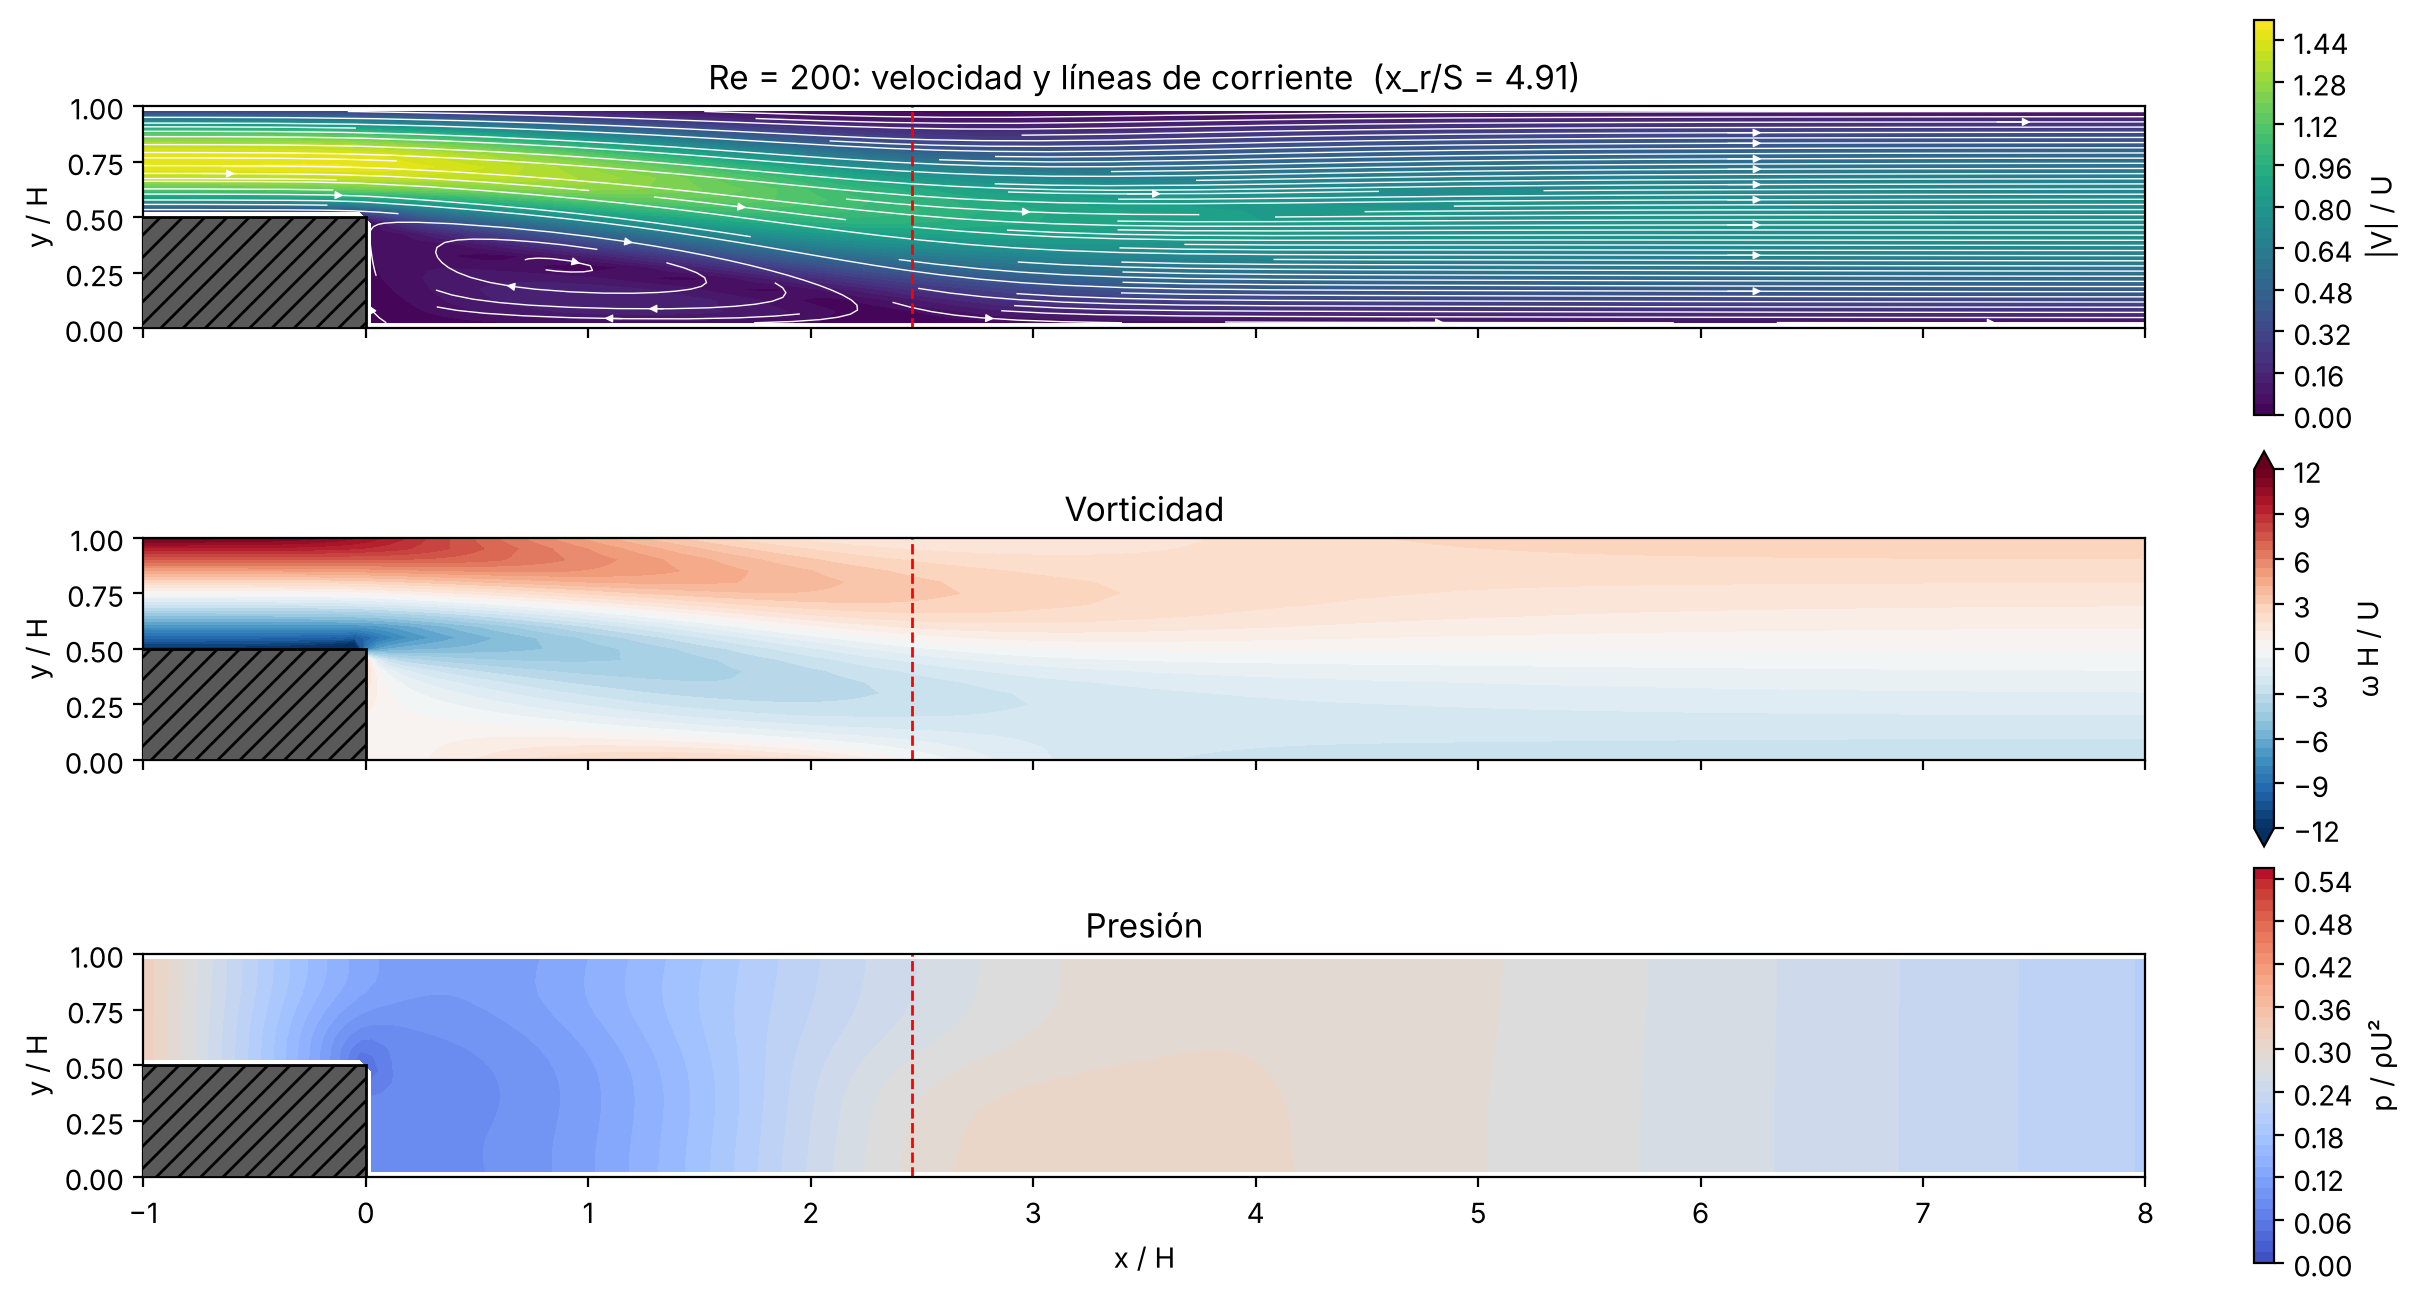

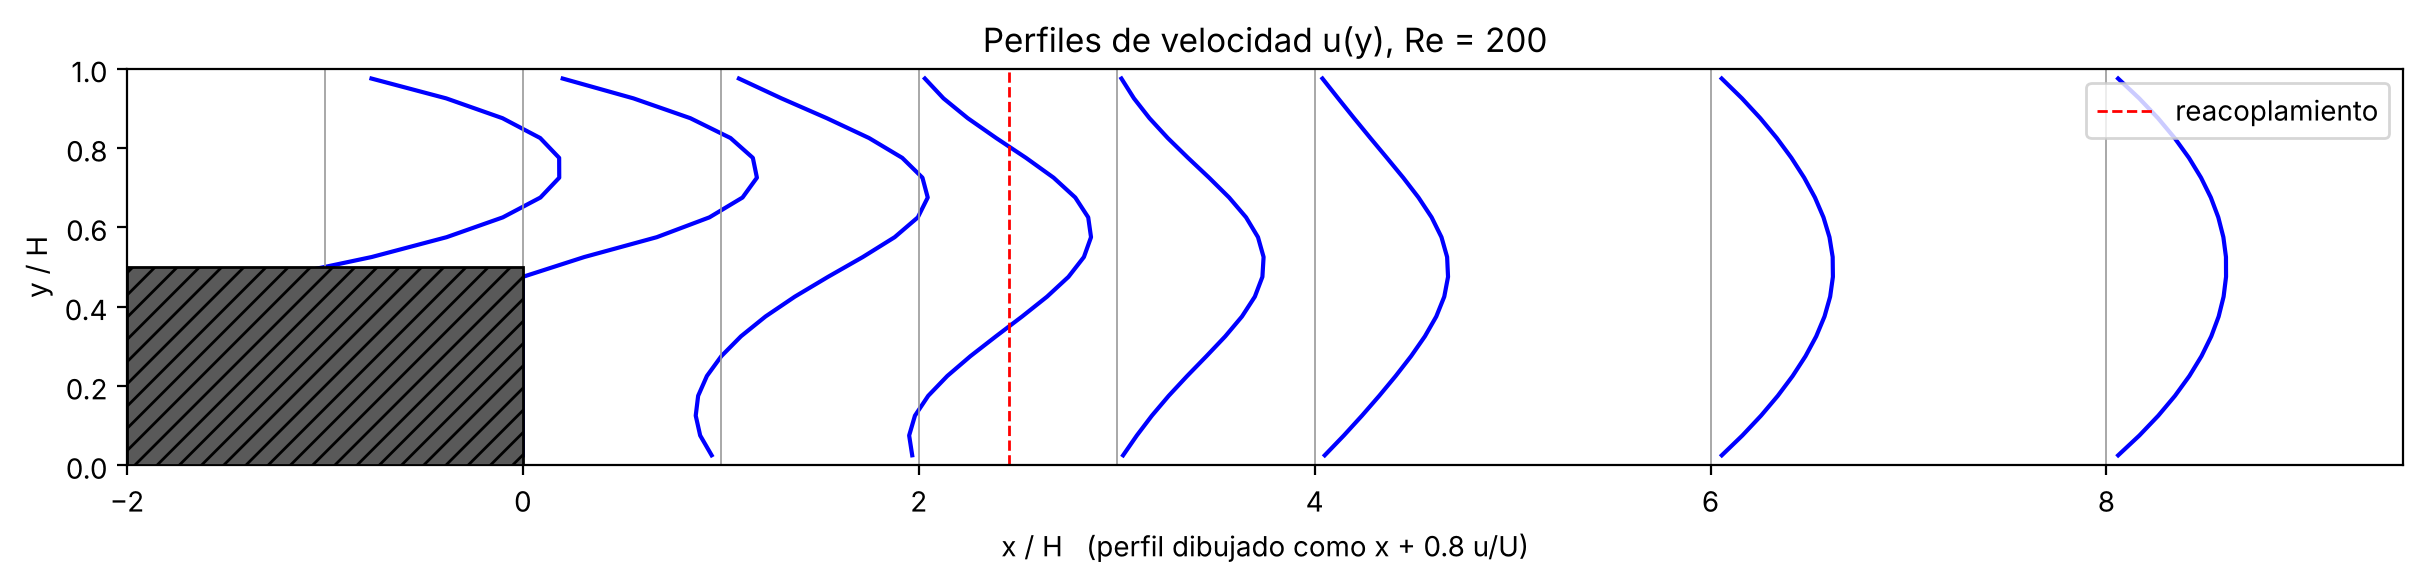

In [12]:
graficar_campos(base, archivo=FIG / "campos_base.png")
graficar_perfiles(base, archivo=FIG / "perfiles_base.png")

**¿Qué se ve?**
* **Velocidad:** el chorro sale del canal de entrada ($u_{max} = 1.5$) y abajo de él queda el remolino. Al final el perfil
  es otra parábola, más baja ($u_{max} = 0.75$) porque el mismo caudal pasa por un canal el doble de alto.
* **Vorticidad:** se concentra en la capa que separa el chorro del remolino (capa de corte), que nace en la esquina.
* **Presión:** sube después del escalón (el fluido se frena al ensancharse el canal, como en Bernoulli). Ese aumento de
  presión, un gradiente adverso, es lo que despega el flujo. Después baja poco a poco por la fricción con las paredes.

### Video: el arranque desde el reposo
Misma $Re$ con una malla el doble de fina (`NY = 40`) para más detalle. Arriba, la tinta; en medio, la vorticidad; abajo,
el largo del remolino contra el tiempo y la velocidad junto al piso.

Re =  200 | NY =  40 | dt = 0.0083 | converge  en t =   43.9 (5273 pasos) | x_r/S = 4.95


/tmp/ipykernel_1991/2976543052.py:35: RuntimeWarning: invalid value encountered in scalar divide
  sub = int(np.ceil(dt / 0.025)); h = dt / sub


video guardado en figures/arranque_re200.mp4


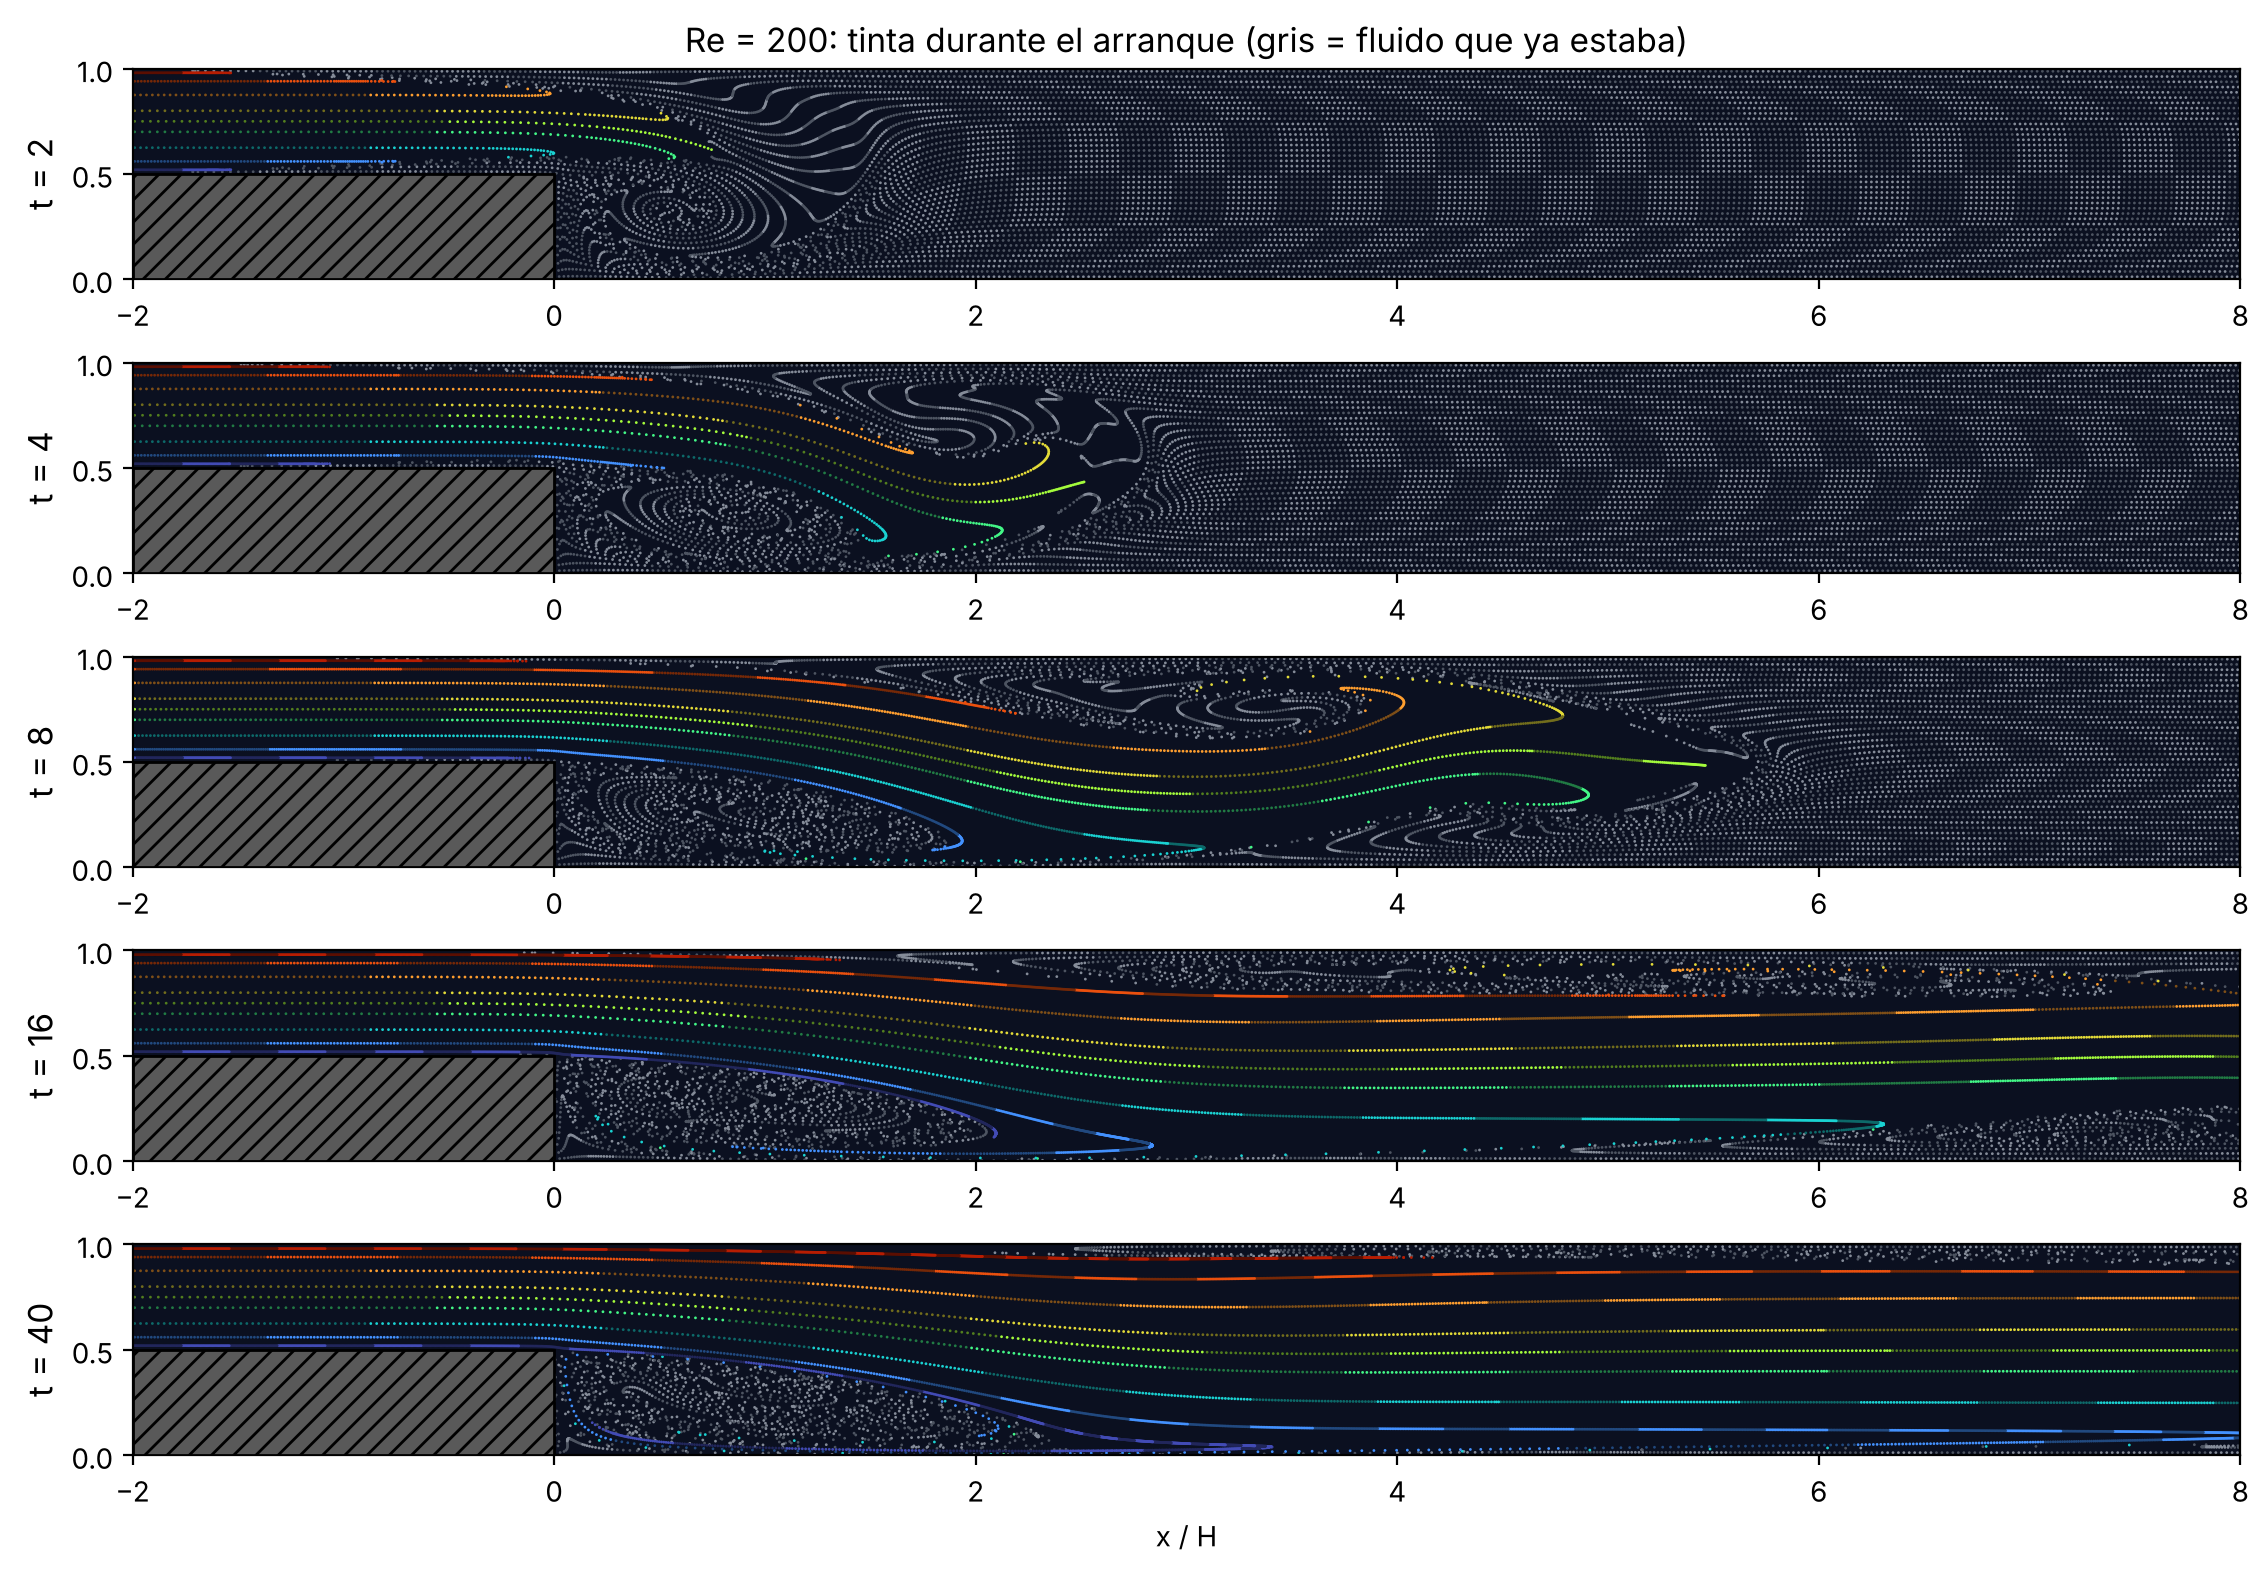

In [13]:
if HACER_VIDEOS:
    detalle = simular(RE, NY=40, L=L, fotos_cada=6)
    animar([detalle], FIG / f"arranque_re{RE}.mp4", x_max=8)
    mostrar_video(FIG / f"arranque_re{RE}.mp4")
    secuencia(detalle, tiempos=[2, 4, 8, 16, 40], archivo=FIG / "secuencia_base.png")

**¿Qué se ve en el video?**
1. **Remolino de arranque** ($t \lesssim 5$): al arrancar, la capa de corte que sale de la esquina se enrolla en un vórtice
   que viaja aguas abajo; la tinta forma una "cabeza de hongo".
2. **Remolinos transitorios en el techo:** el chorro ondula y, por un momento, despega el flujo de la pared de arriba.
3. **Crecimiento lento** del remolino principal hasta su largo final (la curva de $x_r(t)$ se aplana).
4. **Fluido atrapado:** el tablero gris dentro de la burbuja nunca sale; gira en su lugar. La tinta de color pasa por encima
   y sólo la que viene más pegada al escalón roza el borde del remolino.
5. Las franjas de tono (cada unidad de tiempo) dibujan el **perfil de velocidad**: en la entrada forman una parábola.

## 5. Análisis paramétrico
### 5.1 Viscosidad (número de Reynolds)
Se cambia $\nu = 1/Re$. Se usa un canal más largo ($L = 25H$) para que el remolino no llegue a la salida.

In [14]:
lista_re = [100, 200, 300, 400, 500, 600]
casos_re = [simular(Re, NY=20, L=25.0, t_max=500) for Re in lista_re]

print("\n  Re     nu      x_r/S   remolino del techo (en H)")
for r in casos_re:
    b = r["burbuja_sup"]
    techo = f"{b[0]:.2f} a {b[1]:.2f}" if b else "no hay"
    print(f"{r['Re']:5d}  {r['nu']:.4f}  {r['xr']/S:6.2f}   {techo}")

Re =  100 | NY =  20 | dt = 0.0167 | converge  en t =   19.9 (1194 pasos) | x_r/S = 2.84


Re =  200 | NY =  20 | dt = 0.0167 | converge  en t =   43.5 (2608 pasos) | x_r/S = 4.91


Re =  300 | NY =  20 | dt = 0.0167 | converge  en t =   81.5 (4889 pasos) | x_r/S = 6.73


Re =  400 | NY =  20 | dt = 0.0167 | converge  en t =  138.2 (8294 pasos) | x_r/S = 8.26


Re =  500 | NY =  20 | dt = 0.0167 | converge  en t =  216.6 (12997 pasos) | x_r/S = 9.40


Re =  600 | NY =  20 | dt = 0.0167 | converge  en t =  289.0 (17338 pasos) | x_r/S = 10.06

  Re     nu      x_r/S   remolino del techo (en H)
  100  0.0100    2.84   no hay
  200  0.0050    4.91   no hay
  300  0.0033    6.73   no hay
  400  0.0025    8.26   4.20 a 4.50
  500  0.0020    9.40   4.00 a 6.30
  600  0.0017   10.06   4.05 a 7.60


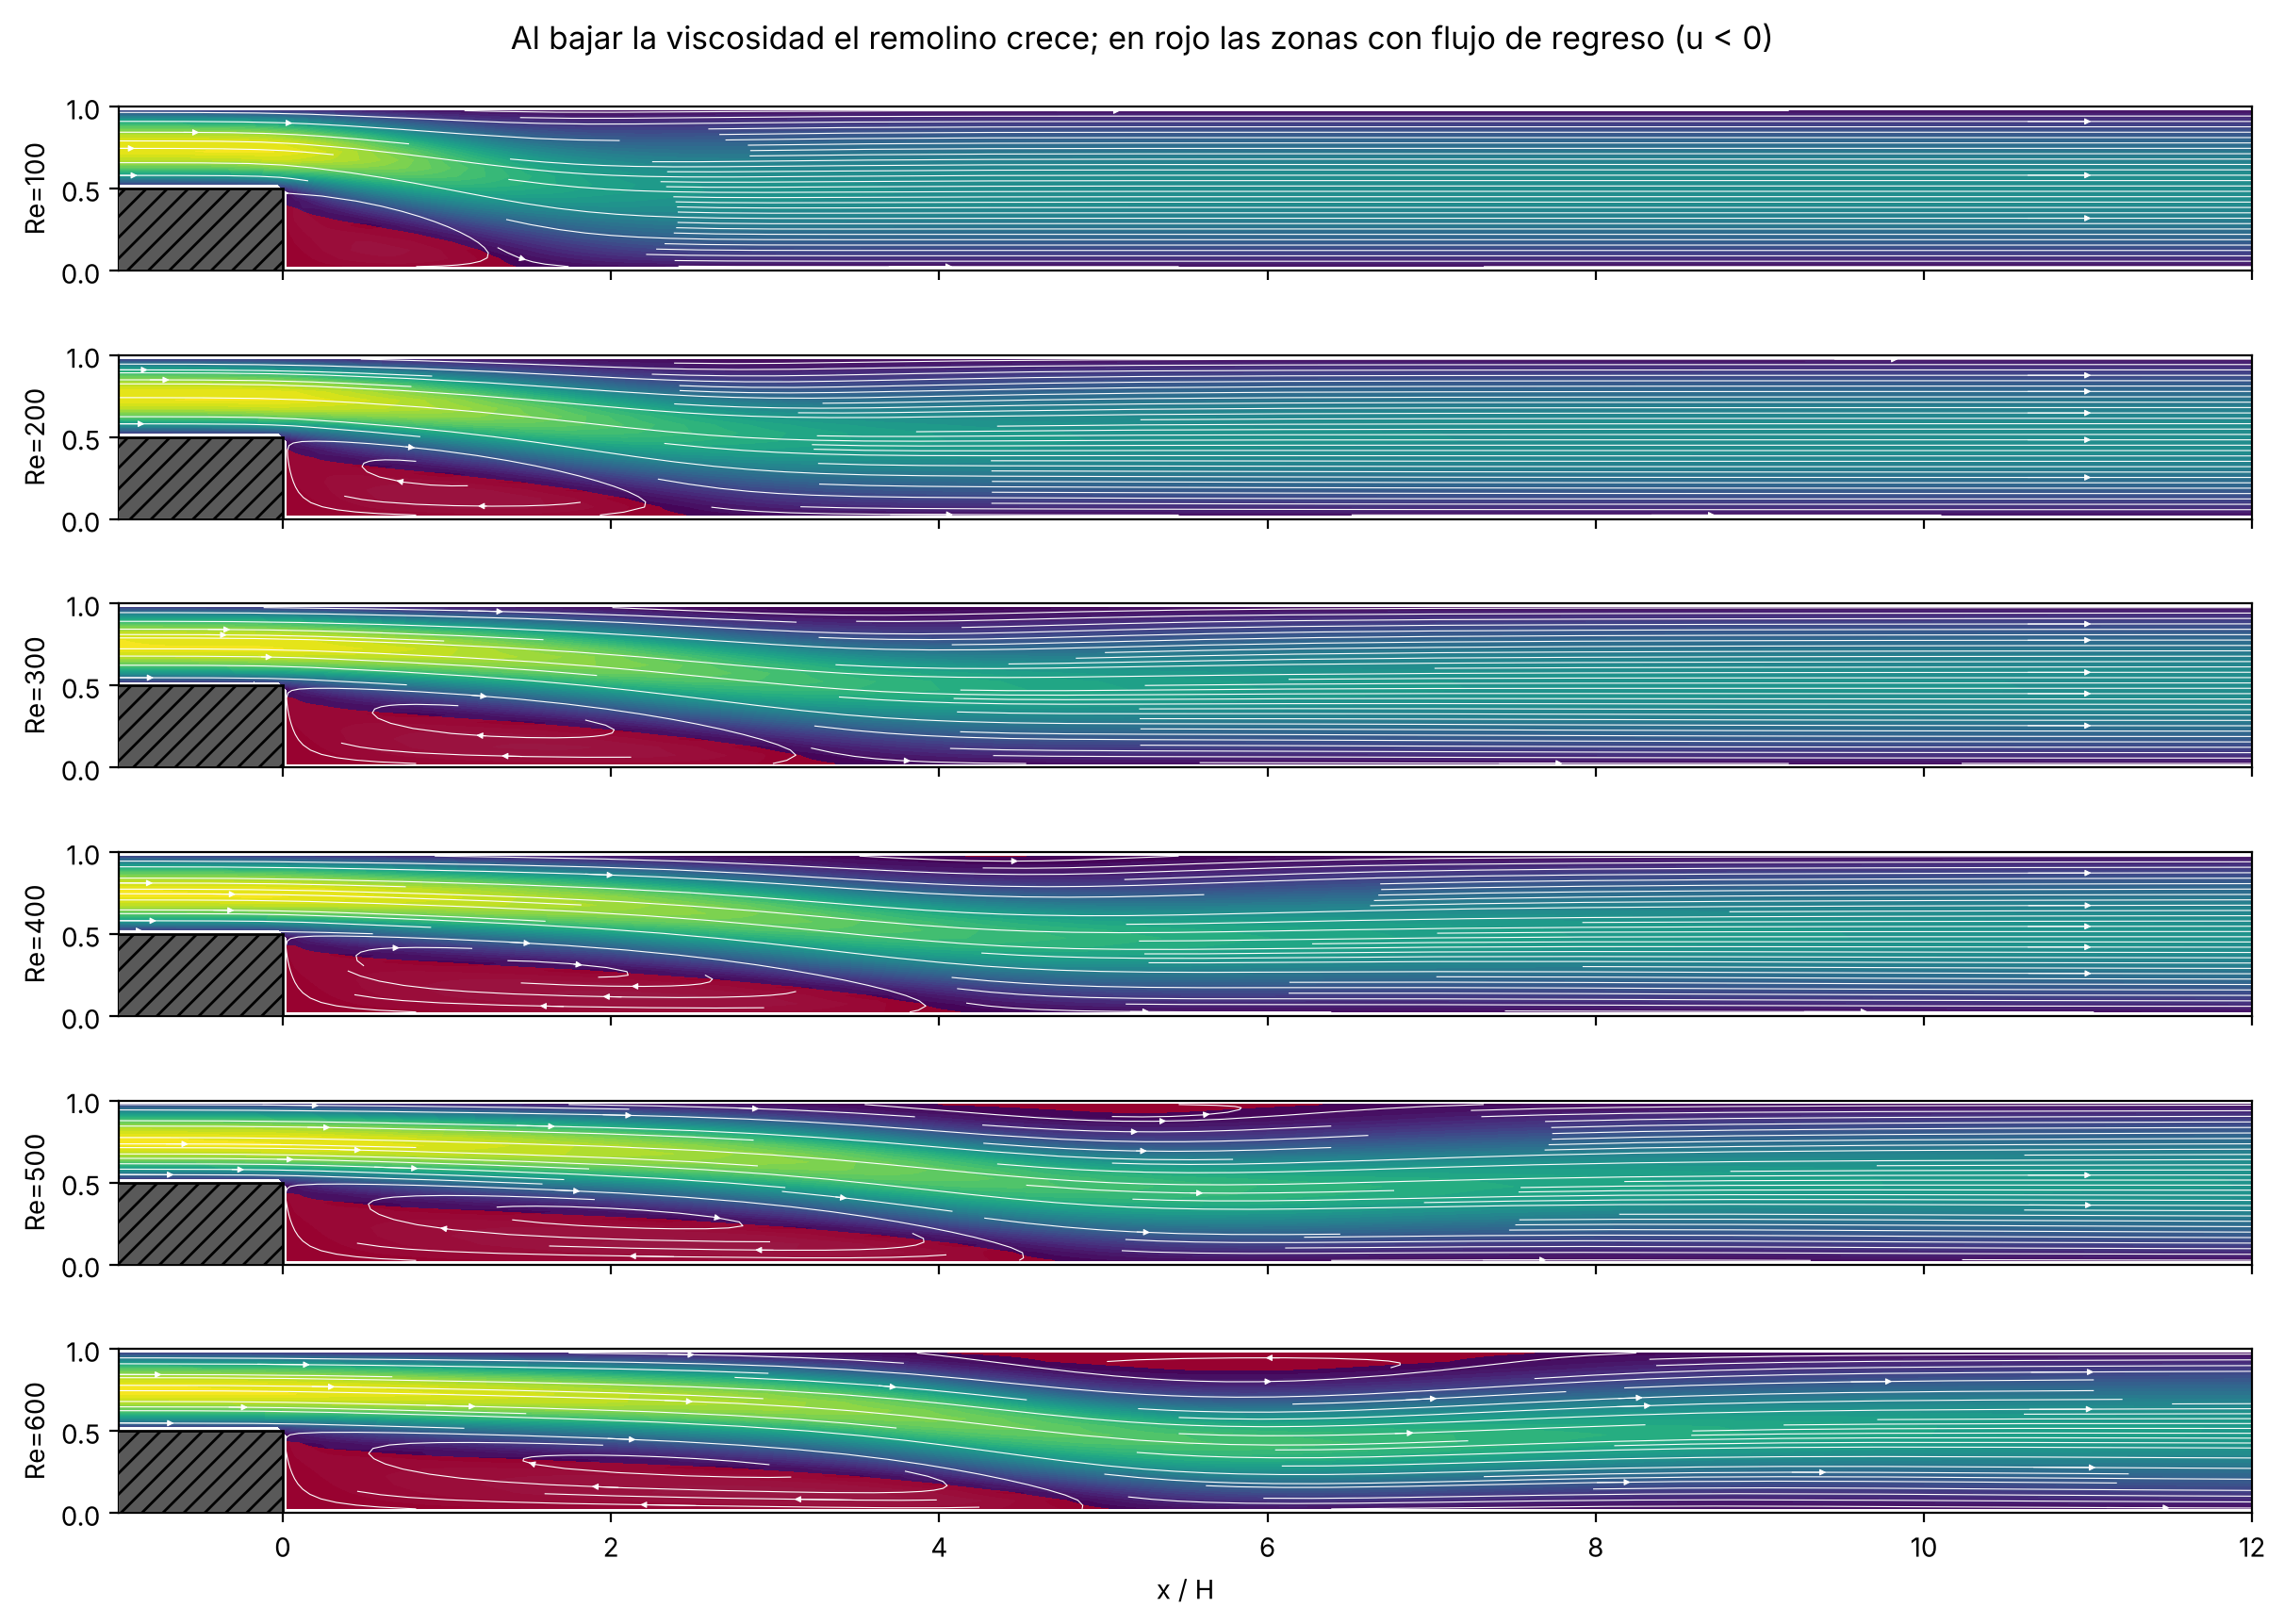

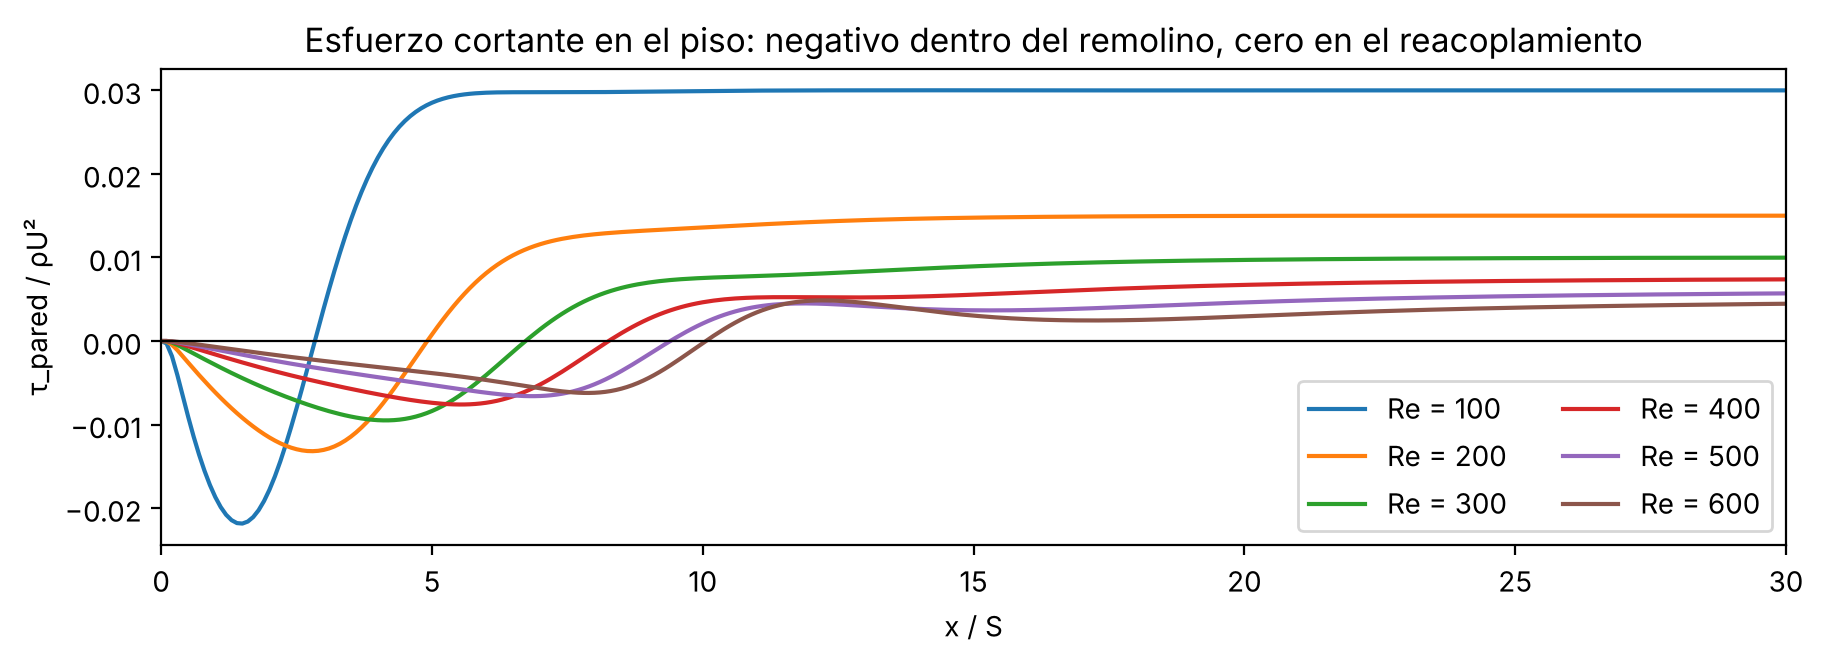

In [15]:
fig, ax = plt.subplots(len(casos_re), 1, figsize=(12, 8.5), sharex=True, constrained_layout=True)
for a, r in zip(ax, casos_re):
    m = r["m"]; uc, vc = velocidad_en_centros(m, r["u"], r["v"])
    a.contourf(m["x_p"], m["y_p"], np.hypot(uc, vc).T, levels=40, cmap="viridis")
    a.contourf(m["x_p"], m["y_p"], uc.T, levels=[-10, 0], colors="red", alpha=0.45)   # rojo: flujo de regreso (u < 0)
    a.streamplot(m["x_p"], m["y_p"], np.nan_to_num(uc.T), np.nan_to_num(vc.T), color="w", density=1.0, linewidth=0.4, arrowsize=0.5)
    dibujar_escalon(a); a.set_xlim(-1, 12); a.set_ylim(0, H); a.set_aspect("equal"); a.set_ylabel(f"Re={r['Re']}")
ax[-1].set_xlabel("x / H")
fig.suptitle("Al bajar la viscosidad el remolino crece; en rojo las zonas con flujo de regreso (u < 0)")
fig.savefig(FIG / "re_remolinos.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(9, 3.2), constrained_layout=True)
for r in casos_re:
    I0 = r["m"]["I0"]
    tau = r["nu"] * r["u"][I0:, 1] / (0.5 * r["m"]["dx"])        # esfuerzo cortante en el piso: nu * du/dy
    ax.plot(r["m"]["x_u"][I0:] / S, tau, label=f"Re = {r['Re']}")
ax.axhline(0, color="k", lw=0.8); ax.set_xlim(0, 30); ax.legend(ncol=2)
ax.set_xlabel("x / S"); ax.set_ylabel("τ_pared / ρU²")
ax.set_title("Esfuerzo cortante en el piso: negativo dentro del remolino, cero en el reacoplamiento")
fig.savefig(FIG / "re_cortante.png", dpi=150); plt.show()

Con menos viscosidad el chorro tarda más en "contagiar" su movimiento hacia el piso (la difusión viscosa es más lenta
frente a la convección), así que el remolino se alarga: **$x_r$ crece casi proporcional a $Re$**. Desde $Re \approx 400$
aparece un remolino en el techo, que empuja el chorro hacia abajo y frena el crecimiento del remolino de abajo.

**Video comparativo:** los tres arranques al mismo tiempo. A $Re = 100$ todo se calma rápido; a $Re = 600$ se forman
varios remolinos que viajan, se juntan y despegan el flujo del techo antes de llegar al estado final.

In [16]:
if HACER_VIDEOS:
    casos_video = [simular(Re, NY=20, L=25.0, t_max=100, fotos_cada=6) for Re in (100, 300, 600)]
    animar(casos_video, FIG / "comparacion_re.mp4", x_max=12)
    mostrar_video(FIG / "comparacion_re.mp4")
    del casos_video

Re =  100 | NY =  20 | dt = 0.0167 | converge  en t =   19.9 (1194 pasos) | x_r/S = 2.84


Re =  300 | NY =  20 | dt = 0.0167 | converge  en t =   81.5 (4889 pasos) | x_r/S = 6.73


Re =  600 | NY =  20 | dt = 0.0167 | tiempo máximo en t =  100.0 (6001 pasos) | x_r/S = 9.35


/tmp/ipykernel_1991/2976543052.py:35: RuntimeWarning: invalid value encountered in scalar divide
  sub = int(np.ceil(dt / 0.025)); h = dt / sub


video guardado en figures/comparacion_re.mp4


### 5.2 Malla
Mismo caso (Re = 200) con 10, 20 y 40 celdas en la altura. Si al refinar el resultado casi no cambia, la malla es suficiente.

Re =  200 | NY =  10 | dt = 0.0333 | converge  en t =   41.8 (1255 pasos) | x_r/S = 4.75


Re =  200 | NY =  20 | dt = 0.0167 | converge  en t =   43.5 (2608 pasos) | x_r/S = 4.91


Re =  200 | NY =  40 | dt = 0.0083 | converge  en t =   43.9 (5273 pasos) | x_r/S = 4.95
NY =  10  (  1600 celdas con fluido)   x_r/S = 4.754
NY =  20  (  6400 celdas con fluido)   x_r/S = 4.914
NY =  40  ( 25600 celdas con fluido)   x_r/S = 4.946


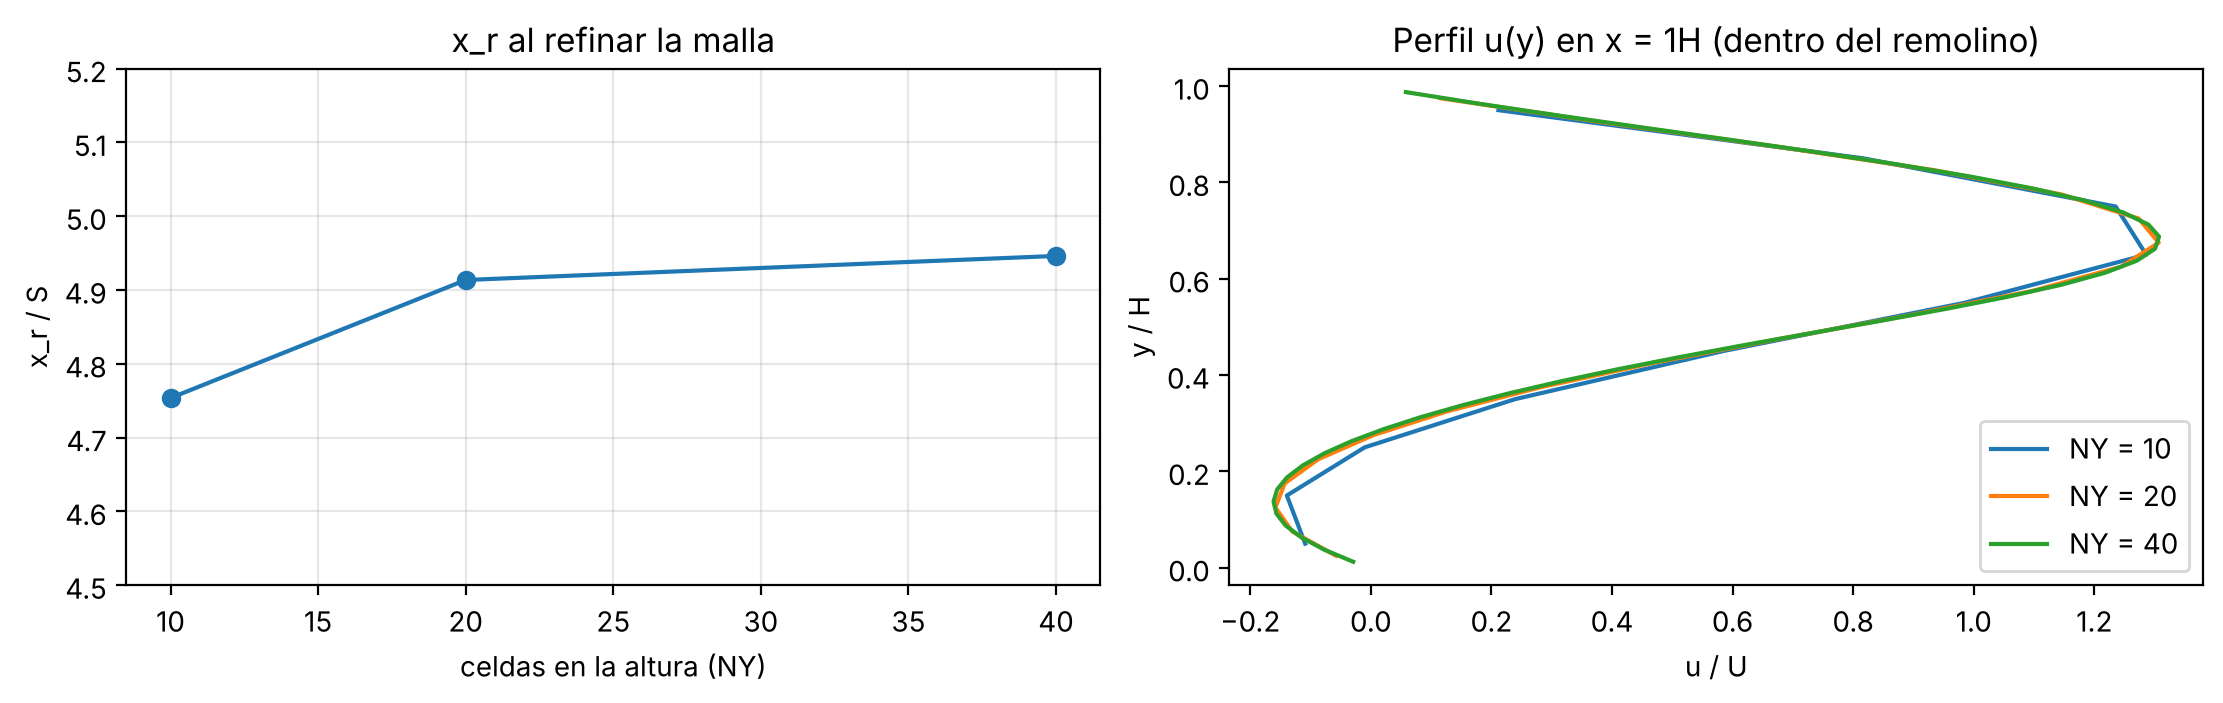

In [17]:
lista_ny = [10, 20, 40]
casos_malla = [simular(200, NY=ny, L=15.0) for ny in lista_ny]
for ny, r in zip(lista_ny, casos_malla):
    print(f"NY = {ny:3d}  ({(~r['m']['solido']).sum():6d} celdas con fluido)   x_r/S = {r['xr']/S:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), constrained_layout=True)
ax[0].plot(lista_ny, [r["xr"] / S for r in casos_malla], "o-")
ax[0].set_xlabel("celdas en la altura (NY)"); ax[0].set_ylabel("x_r / S"); ax[0].set_title("x_r al refinar la malla")
ax[0].set_ylim(4.5, 5.2); ax[0].grid(alpha=0.3)
for r, ny in zip(casos_malla, lista_ny):
    i = r["m"]["I0"] + round(1.0 / r["m"]["dx"])
    ax[1].plot(r["u"][i, 1:-1], r["m"]["y_p"], label=f"NY = {ny}")
ax[1].set_xlabel("u / U"); ax[1].set_ylabel("y / H"); ax[1].set_title("Perfil u(y) en x = 1H (dentro del remolino)"); ax[1].legend()
fig.savefig(FIG / "malla.png", dpi=150); plt.show()

De 10 a 20 celdas $x_r$ cambia 3.4 % y de 20 a 40 sólo 0.7 %: **el resultado ya casi no depende de la malla**.
El cambio se reduce unas 5 veces cada vez que se duplica la malla, como se espera de un método con error $\propto \Delta x^2$
(al menos 4 veces). Así, con 20 celdas el error es menor a 1 %.
Con 20 celdas el cálculo es unas 10 veces más rápido que con 40 (4 veces menos celdas y el doble de $\Delta t$).

### 5.3 Paso de tiempo
Re = 200, NY = 20. El límite CFL es $\Delta t = \Delta x/u_{max} = 0.05/1.5 = 0.033$. Probamos 0.25, 0.5, 0.8 y 1.0 veces ese
límite, y también Euler simple (sin Adams–Bashforth) con el $\Delta t$ normal.

Re =  200 | NY =  20 | dt = 0.0083 | converge  en t =   43.5 (5215 pasos) | x_r/S = 4.91


Re =  200 | NY =  20 | dt = 0.0167 | converge  en t =   43.5 (2608 pasos) | x_r/S = 4.91


Re =  200 | NY =  20 | dt = 0.0267 | converge  en t =   43.5 (1631 pasos) | x_r/S = 4.91
Re =  200 | NY =  20 | dt = 0.0333 | diverge   en t =    1.2 (36 pasos)


Re =  200 | NY =  20 | dt = 0.0167 | diverge   en t =   11.8 (706 pasos)


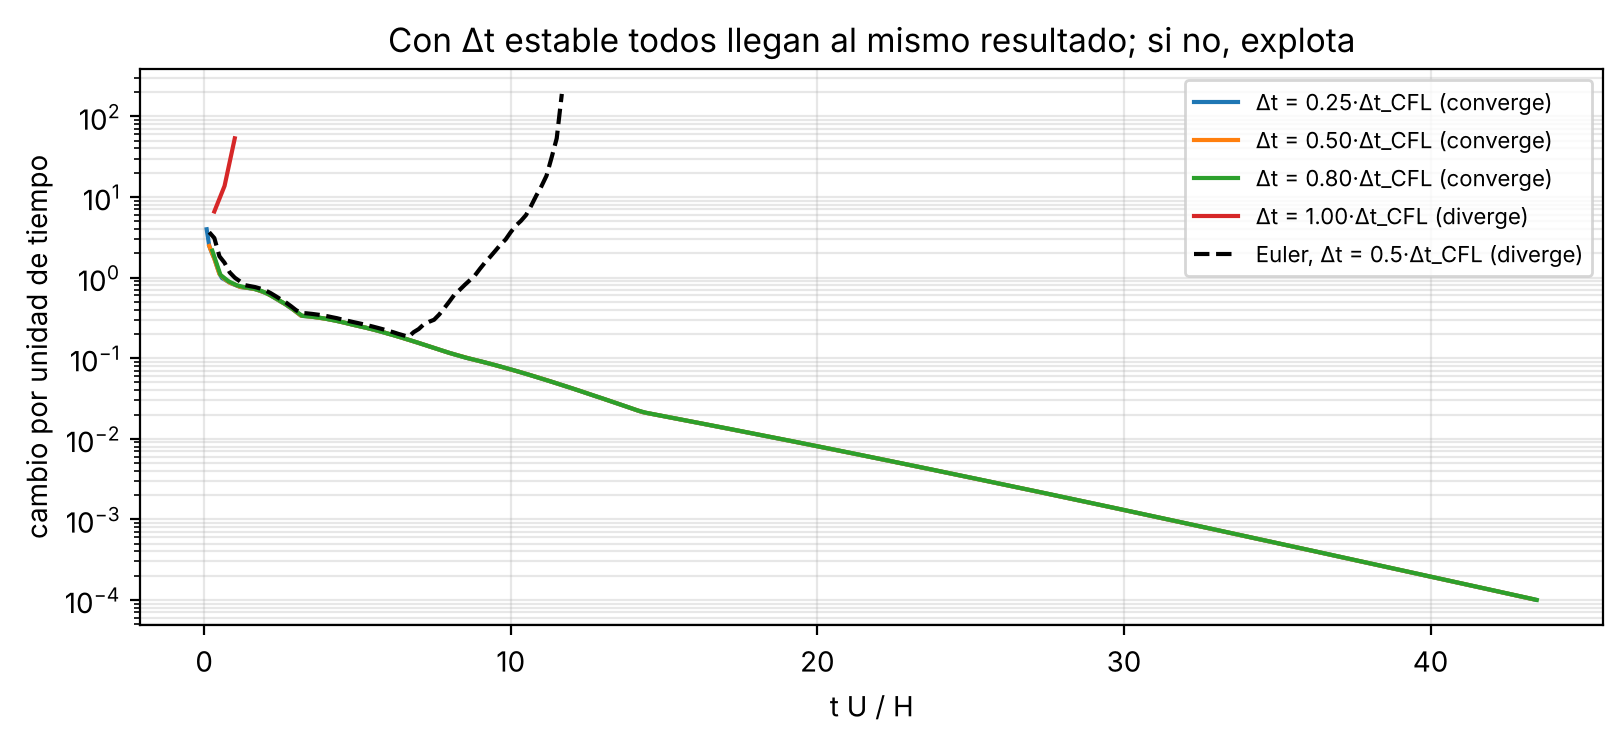

In [18]:
dt_cfl = (H / 20) / 1.5
casos_dt = [simular(200, NY=20, L=15.0, dt=f * dt_cfl, t_max=150) for f in (0.25, 0.5, 0.8, 1.0)]
euler = simular(200, NY=20, L=15.0, t_max=150, ab2=False)

fig, ax = plt.subplots(figsize=(8, 3.6), constrained_layout=True)
for r in casos_dt:
    ax.semilogy(r["hist_t"], r["hist_cambio"], label=f"Δt = {r['dt']/dt_cfl:.2f}·Δt_CFL ({r['estado']})")
ax.semilogy(euler["hist_t"], euler["hist_cambio"], "k--", label=f"Euler, Δt = 0.5·Δt_CFL ({euler['estado']})")
ax.set_xlabel("t U / H"); ax.set_ylabel("cambio por unidad de tiempo"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
ax.set_title("Con Δt estable todos llegan al mismo resultado; si no, explota")
fig.savefig(FIG / "dt.png", dpi=150); plt.show()

Mientras $\Delta t$ es estable, el resultado final es **idéntico** ($x_r/S = 4.91$): un $\Delta t$ más grande sólo
llega en menos pasos. En el límite CFL (1.0) la solución explota en pocas decenas de pasos. Euler simple explota aunque
$\Delta t$ sea pequeño: por eso usamos Adams–Bashforth.

## 6. Comparación con la literatura
Valores de $x_r/S$ de simulaciones 2D publicadas para este mismo problema (tabla recopilada en arXiv:2507.16509;
la tendencia coincide con los experimentos de Armaly et al., 1983, hasta $Re \approx 400$).

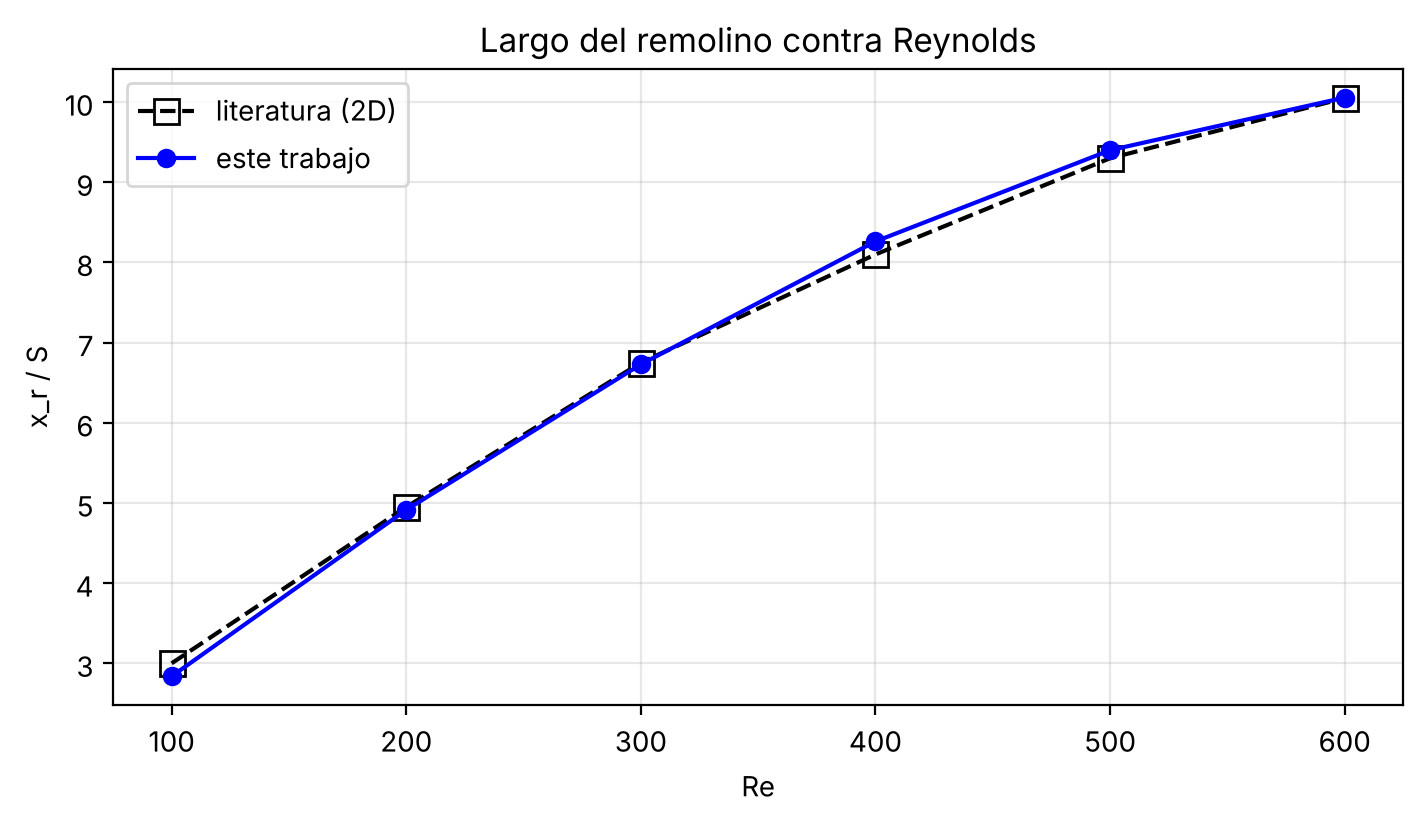

Re =  100   nuestro =  2.84   literatura =  3.00   diferencia = -5.4 %
Re =  200   nuestro =  4.91   literatura =  4.95   diferencia = -0.7 %
Re =  300   nuestro =  6.73   literatura =  6.75   diferencia = -0.3 %
Re =  400   nuestro =  8.26   literatura =  8.10   diferencia = +2.0 %
Re =  500   nuestro =  9.40   literatura =  9.30   diferencia = +1.1 %
Re =  600   nuestro = 10.06   literatura = 10.05   diferencia = +0.1 %


In [19]:
re_lit = [100, 200, 300, 400, 500, 600]
xr_lit = [3.00, 4.95, 6.75, 8.10, 9.30, 10.05]

fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.plot(re_lit, xr_lit, "ks--", mfc="none", ms=9, label="literatura (2D)")
ax.plot(lista_re, [r["xr"] / S for r in casos_re], "bo-", label="este trabajo")
ax.set_xlabel("Re"); ax.set_ylabel("x_r / S"); ax.grid(alpha=0.3); ax.legend()
ax.set_title("Largo del remolino contra Reynolds")
fig.savefig(FIG / "validacion.png", dpi=150); plt.show()

for r, ref in zip(casos_re, xr_lit):
    print(f"Re = {r['Re']:4d}   nuestro = {r['xr']/S:5.2f}   literatura = {ref:5.2f}   diferencia = {100*(r['xr']/S - ref)/ref:+.1f} %")

Entre $Re = 200$ y $600$ las diferencias son de 2 % o menos; en $Re = 100$, el remolino más corto, de unos 5 %. Como el
estudio de malla mostró que el resultado ya no cambia al refinar, estas diferencias no son error numérico nuestro:
son del tamaño de las diferencias entre los propios estudios publicados (por detalles como el largo del canal de entrada).

## Conclusiones
1. Resolvimos Navier–Stokes 2D con el método de proyección: velocidad de prueba → presión → corrección. La masa se conserva
   a precisión de máquina.
2. La simulación muestra la separación en la esquina, el remolino, el reacoplamiento y, para $Re \ge 400$, el remolino del techo.
   El video muestra además cómo se forman: vórtice de arranque, remolinos transitorios y fluido atrapado en la burbuja.
3. **Viscosidad:** al bajarla (subir $Re$) el remolino crece, de $x_r/S \approx 2.8$ en Re = 100 a 10 en Re = 600.
4. **Malla:** con convección por promedio el resultado converge rápido; con 20 celdas el error es menor a 1 %.
5. **Paso de tiempo:** no cambia el resultado mientras se cumpla el CFL; si no, la solución explota. Euler simple no sirve
   con este esquema; Adams–Bashforth sí.
6. Coincidencia con la literatura dentro de 2 % para $200 \le Re \le 600$.

**Referencias:** Armaly et al. (1983) *J. Fluid Mech.* 127; Gartling (1990) *Int. J. Numer. Methods Fluids* 11;
Chorin (1968) *Math. Comp.* 22; Harlow y Welch (1965) *Phys. Fluids* 8; arXiv:2507.16509 (2025);
kangluosee, *CFD-Python* (GitHub).